# 📊 TOBIG'S 6주차 과제 — 데이터 시각화

세션에서 다룬 내용(*Fundamentals of Data Visualization*, Claus O. Wilke)을 직접 코드로 확인해 보는 과제입니다.

### 진행 방법
- 라이브러리는 **plotnine**을 사용합니다. R의 **ggplot2** 문법을 파이썬으로 옮긴 라이브러리라서 `ggplot(데이터, aes(...)) + geom_*()` 구조가 똑같습니다.
- 코드의 `____` 부분을 채워 셀을 실행하세요.
- 🔧 **고치기** 문제는 주어진 *나쁜 차트*를 세션 내용에 맞게 고치는 문제입니다.
- 📝 표시가 있는 문제는 **✍️ 답:** 칸에 2~3문장으로 답을 작성하세요.
- Colab의 한글 폰트 문제를 피하기 위해 **그래프 안의 라벨은 영어로** 작성합니다.

### 목차
1. 시각적 속성과 스케일
2. 위치 스케일 (선형 / 로그)
3. 색상 스케일 (정성적 / 강조 / 순차적 / 발산형)
4. 수량 데이터 (막대, 묶은·누적 막대, 점 도표, 순서형 범주)
5. 분포 데이터 (히스토그램, 밀도 도표, 여러 분포 비교)
6. 종합 문제

## 0. 준비

In [4]:
# Colab에는 plotnine이 기본 설치되어 있습니다. 없다는 에러가 나면 아래 줄의 주석을 풀고 실행하세요.
# !pip install -q plotnine

import numpy as np
import pandas as pd
from plotnine import *
from plotnine.data import mtcars, mpg, midwest, txhousing, faithful, penguins

# 세션에서 소개한 Okabe-Ito 정성적 팔레트 (색각 이상이 있어도 구분하기 쉬운 팔레트)
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]

theme_set(theme_minimal() + theme(figure_size=(7, 4.5)))

## 1. 시각적 속성과 스케일

세션에서 **시각적 속성 = 값을 정량화 → 그래픽으로 표현**하는 것이고, **스케일**은 값과 시각적 속성을 연결하는 방식이라고 배웠습니다.
슬라이드 7의 자동차 산점도는 `mtcars` 데이터로 그린 그래프이며, **5개의 스케일**을 사용합니다.

### 문제 1-1 (빈칸)
`mtcars`로 슬라이드 7의 그래프를 재현하세요.

| 변수 | 의미 | 시각적 속성 |
|---|---|---|
| `disp` | 배기량 | x 위치 |
| `mpg` | 연비 | y 위치 |
| `hp` | 마력 | 색상 |
| `wt` | 무게 | 크기 |
| `cyl` | 실린더 수 | 모양 |

Matplotlib is building the font cache; this may take a moment.


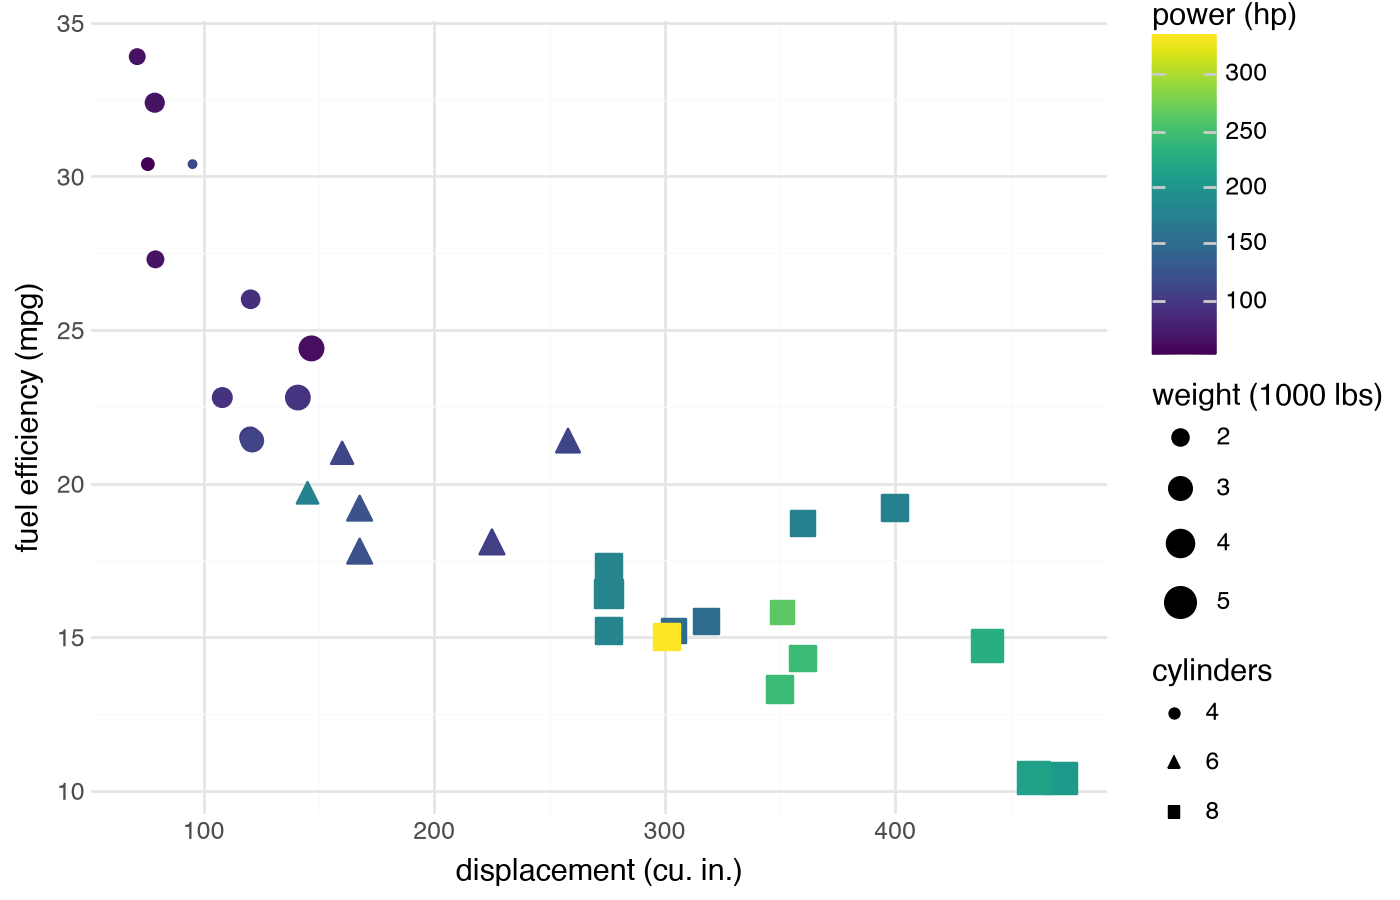

In [7]:
(
    ggplot(mtcars, aes(x="disp", y="mpg",
                       color="hp",          # 마력
                       size="wt",           # 무게
                       shape="factor(cyl)"))         # 실린더 수 (힌트: 범주형으로 바꿔야 합니다)
    + geom_point()
    + scale_color_cmap("viridis")
    + labs(x="displacement (cu. in.)", y="fuel efficiency (mpg)",
           color="power (hp)", size="weight (1000 lbs)", shape="cylinders")
)

### 문제 1-2 📝
`shape`에 `"cyl"` 대신 `"factor(cyl)"`을 넣어야 하는 이유는 무엇일까요? **모양**이라는 시각적 속성이 표현할 수 있는 데이터 종류와 연결해서 설명하세요.

**✍️ 답:** 숫자로 저장된 `cyl`을 `factor(cyl)`로 범주형으로 바꾸어 4, 6, 8기통을 각각 다른 모양으로 표현해야 한다. 모양은 서로 다른 범주를 구분하는 데 적합하지만 수치 자체를 연속적으로 표현할 수는 없다.

## 2. 위치 스케일 — 로그 스케일

슬라이드 13에서는 텍사스 카운티 인구를 **중간값으로 나눈 비율**로 그렸습니다.
선형 스케일에서는 몇몇 대도시 때문에 나머지 카운티가 바닥에 깔려 보이지 않았고, 로그 스케일을 쓰자 전체 구조가 드러났습니다.

여기서는 미국 중서부 5개 주, 437개 카운티 데이터인 `midwest`로 같은 분석을 해봅니다.

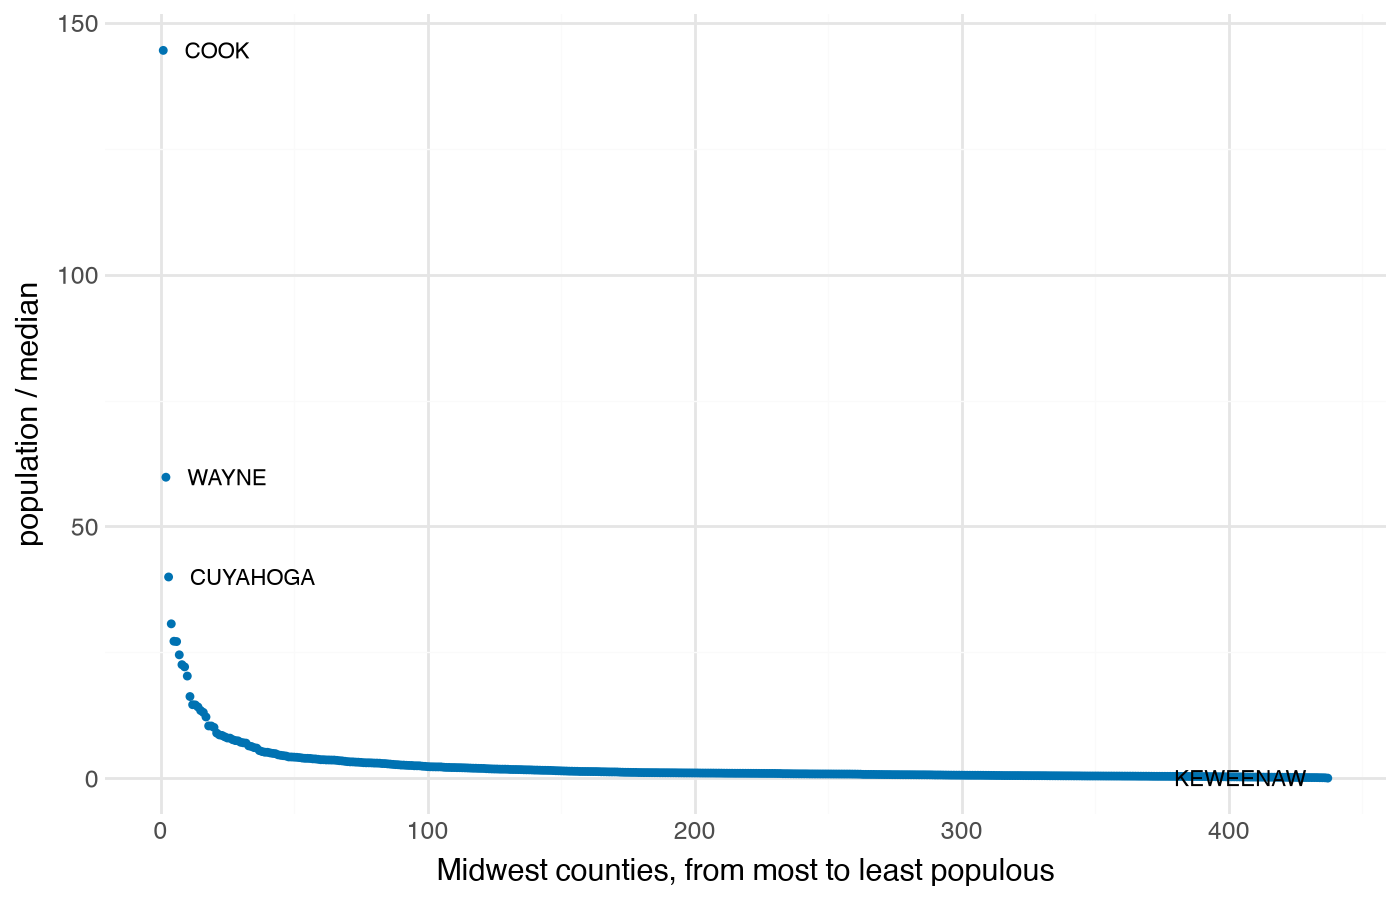

In [8]:
# 인구를 중간값으로 나눈 비율, 인구가 많은 순으로 순위 매기기
county = midwest[["county", "state", "poptotal"]].copy()
county["ratio"] = county["poptotal"] / county["poptotal"].median()
county = county.sort_values("ratio", ascending=False).reset_index(drop=True)
county["rank"] = np.arange(1, len(county) + 1)

# 라벨을 붙일 카운티: 상위 3개(점 오른쪽에 표시) + 최하위 1개(점 왼쪽에 표시)
p_linear = (
    ggplot(county, aes(x="rank", y="ratio"))
    + geom_point(size=0.8, color="#0072B2")
    + geom_text(aes(label="county"), data=county.head(3), ha="left", nudge_x=8, size=8)
    + geom_text(aes(label="county"), data=county.tail(1), ha="right", nudge_x=-8, size=8)
    + labs(x="Midwest counties, from most to least populous", y="population / median")
)
p_linear

### 문제 2-1 (빈칸)
위 그래프는 선형 스케일이라 대부분의 카운티가 0 근처에 몰려 있습니다. y축을 **로그 스케일**로 바꾸고, 중간값(비율 = 1)에 점선 기준선을 추가하세요.

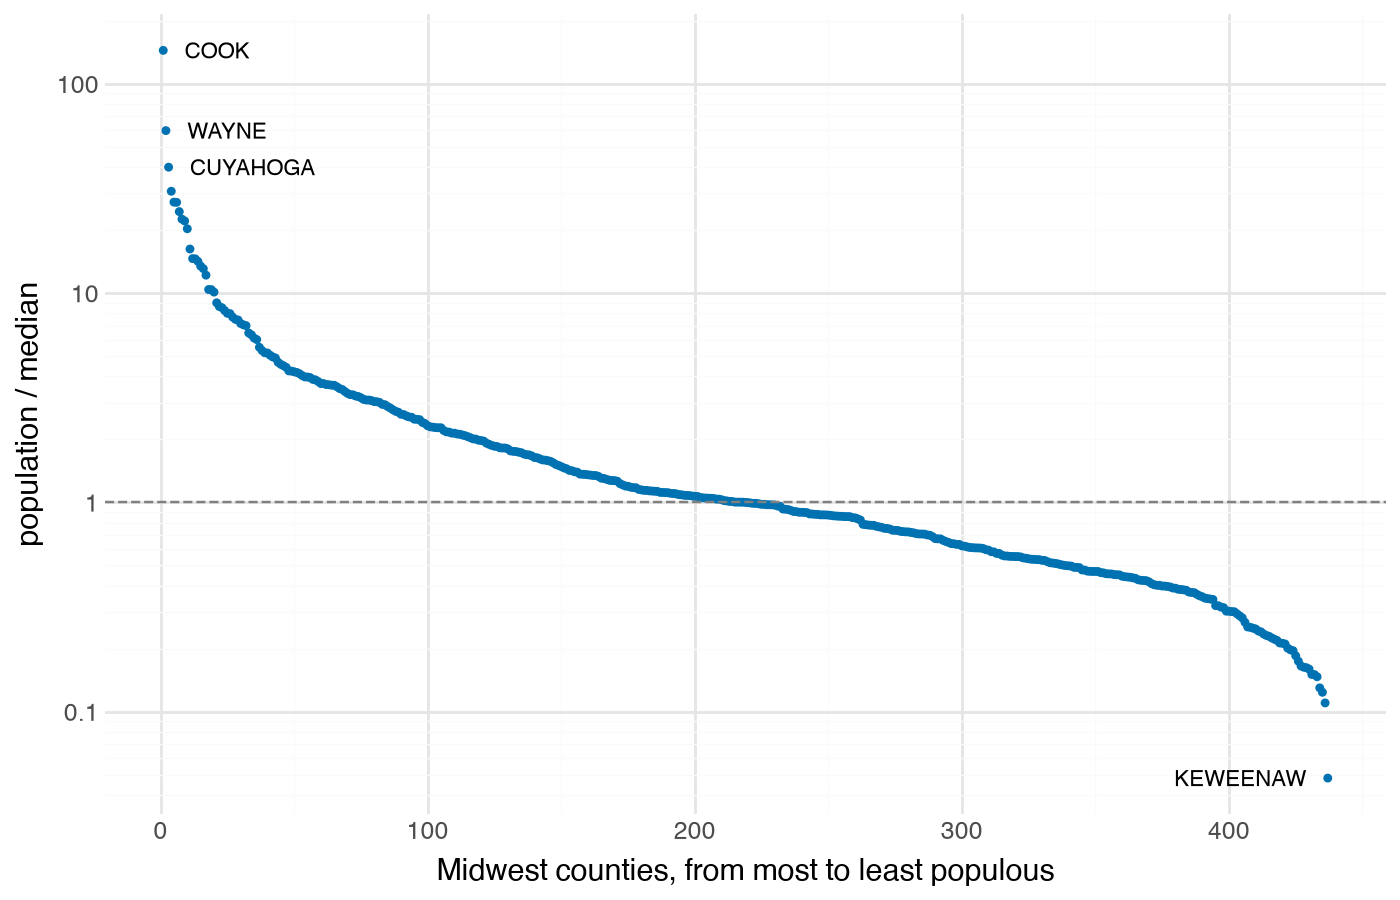

In [9]:
(
    p_linear
    + scale_y_log10()                                                    # TODO: y축 로그 스케일
    + geom_hline(yintercept=1, linetype="dashed", color="gray")    # TODO: 중간값 위치
)

### 문제 2-2 🔧 고치기
슬라이드 11의 *wrong* 사례처럼, 아래 그래프는 **데이터와 축 제목이 맞지 않습니다.**
무엇이 잘못됐는지 찾고, 원본 데이터를 로그 스케일로 올바르게 그리도록 고치세요.

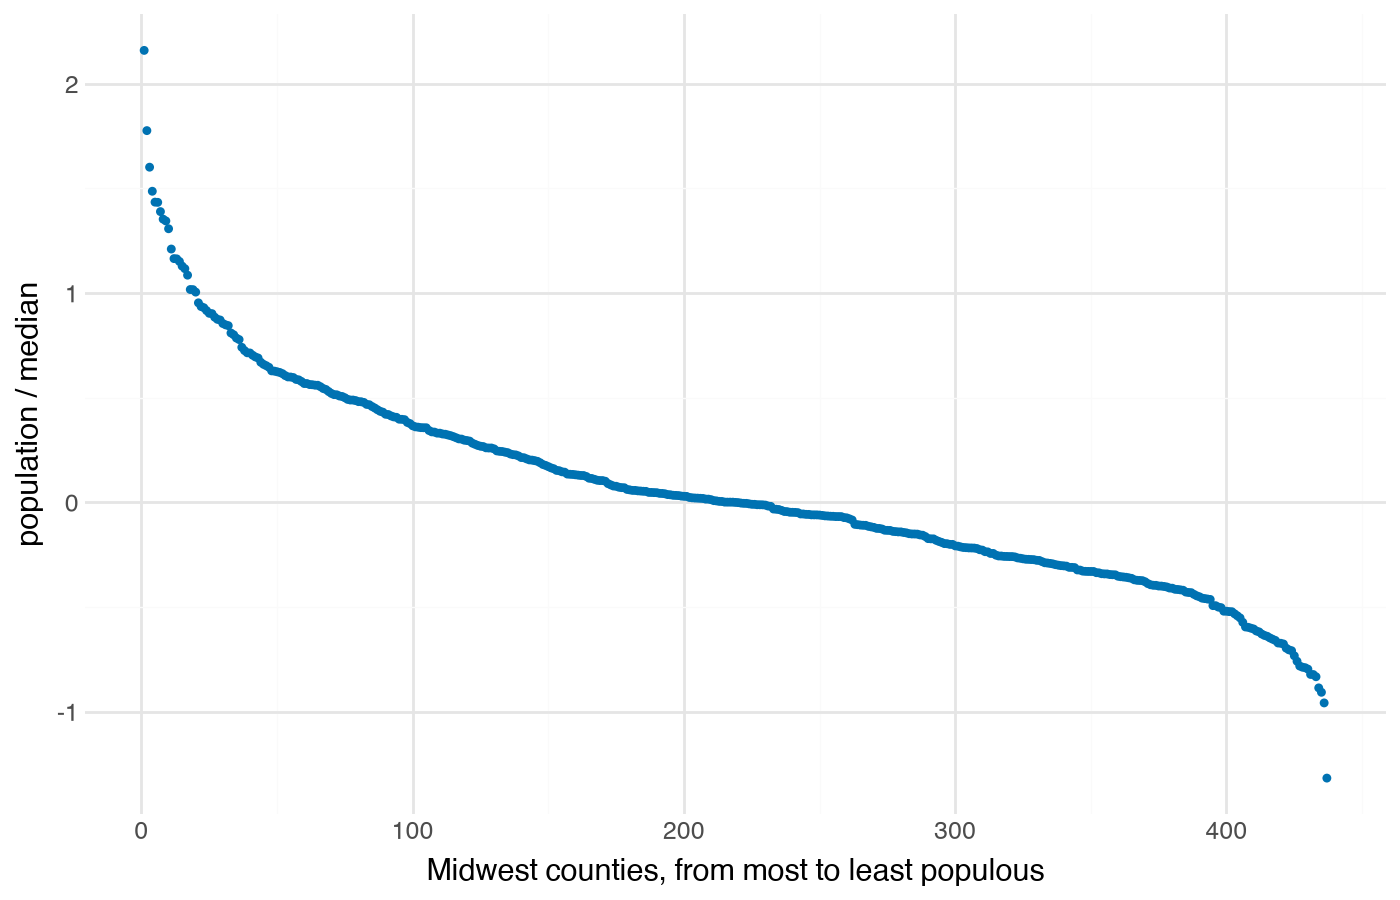

In [10]:
# ❌ 잘못된 그래프 (그대로 두세요)
county["log_ratio"] = np.log10(county["ratio"])

(
    ggplot(county, aes(x="rank", y="log_ratio"))
    + geom_point(size=0.8, color="#0072B2")
    + labs(x="Midwest counties, from most to least populous", y="population / median")
)

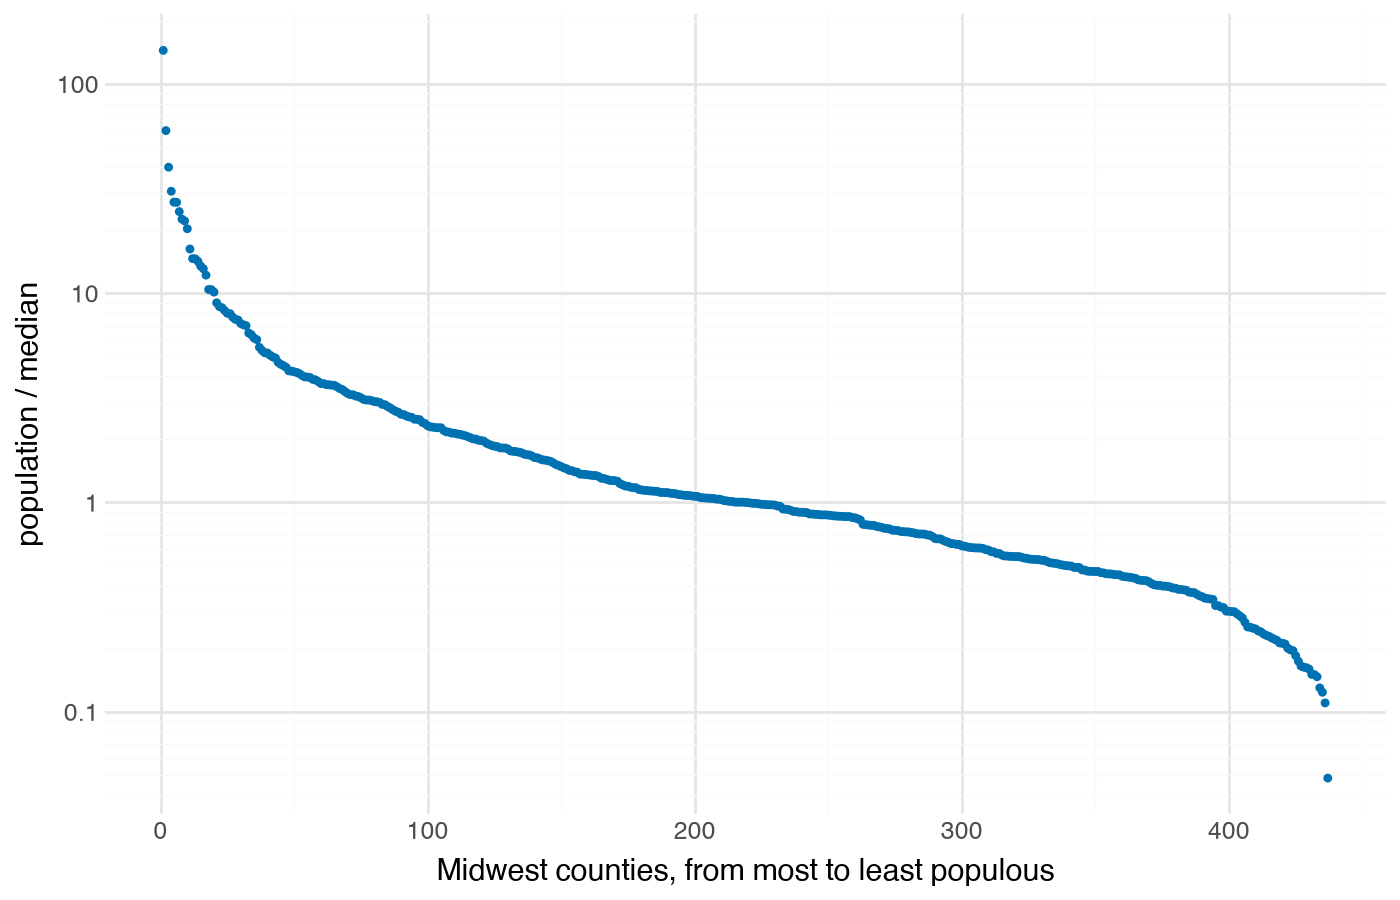

In [11]:
# ✅ 고친 그래프를 작성하세요
# 무엇이 잘못됐는지 주석으로 적어 주세요:
# 기존 그래프는 log10(ratio)를 그리면서 축 제목은 원래 비율로 표시했다.

(
    ggplot(county, aes(x="rank", y="ratio"))
    + geom_point(size=0.8, color="#0072B2")
    + scale_y_log10()
    + labs(x="Midwest counties, from most to least populous", y="population / median")
)

### 문제 2-3 📝
인구 데이터가 아니라 **0이 포함된 데이터**(예: 연간 사고 건수)를 로그 스케일로 그리면 어떤 문제가 생길까요? 세션에서 소개한 대안 스케일은 무엇인가요?

**✍️ 답:** log0은 실수 범위에서 정의되지 못하므로 일반적인 로그 축에서는 0을 표시할 수 없다. 세션에서 소개된 대안인 제곱근 스케일(`scale_y_sqrt()`)은 0을 유지하면서 큰 값의 범위를 압축하므로 값의 범위가 넓은 데이터를 보다 쉽게 비교할 수 있다.

## 3. 색상 스케일

세션에서 배운 색상의 세 가지 목적은 다음과 같습니다.
1. **데이터 그룹 구분**: 정성적 스케일
2. **데이터 값 표현**: 순차적 스케일, 발산형 스케일
3. **특정 값 강조**: 강조 스케일

### 준비: 제조사별 평균 고속도로 연비
`mpg` 데이터의 제조사에 **제조국** 정보를 붙입니다.

In [12]:
COUNTRY = {
    "audi": "Germany", "volkswagen": "Germany",
    "chevrolet": "USA", "dodge": "USA", "ford": "USA", "jeep": "USA",
    "lincoln": "USA", "mercury": "USA", "pontiac": "USA",
    "honda": "Japan", "nissan": "Japan", "subaru": "Japan", "toyota": "Japan",
    "hyundai": "Korea", "land rover": "UK",
}

maker = mpg.groupby("manufacturer", as_index=False, observed=True)["hwy"].mean()
maker["country"] = maker["manufacturer"].map(COUNTRY)
maker.head()

,manufacturer,hwy,country
0,audi,26.444444,Germany
1,chevrolet,21.894737,USA
2,dodge,17.945946,USA
3,ford,19.360000,USA
4,honda,32.555556,Japan


### 문제 3-1 (빈칸) — 정성적 스케일
슬라이드 21처럼 **연비 순으로 정렬한 가로 막대 그래프**를 그리고, 막대 색으로 **제조국**을 구분하세요.
- 막대 순서: `reorder(manufacturer, hwy)`를 쓰면 hwy 값 순서로 정렬됩니다.
- 색상: 순서가 없는 그룹이므로 `OKABE_ITO` 팔레트를 사용합니다.

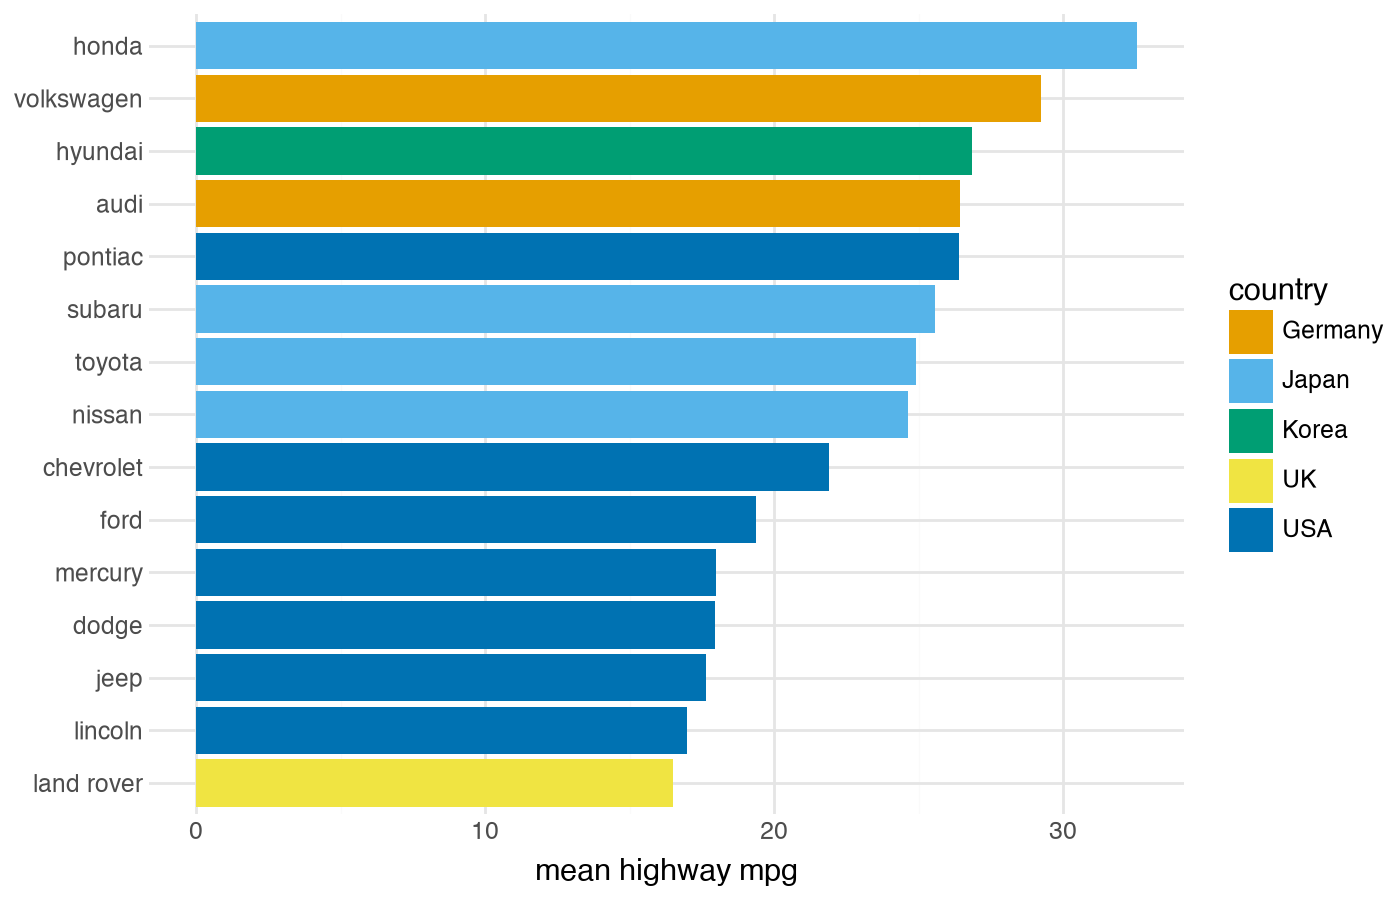

In [13]:
(
    ggplot(maker, aes(x="reorder(manufacturer, hwy)", y="hwy", fill="country"))     # TODO: 정렬된 제조사, 색상으로 구분할 변수
    + geom_col()
    + coord_flip()                                    # TODO: 막대를 가로로
    + scale_fill_manual(values=OKABE_ITO)                  # TODO: 정성적 팔레트
    + labs(x="", y="mean highway mpg", fill="country")
)

### 문제 3-2 (빈칸) — 강조 스케일
이번에는 **한국 제조사(hyundai)만 강조**하려고 합니다. 슬라이드 27처럼 나머지는 평이한 회색으로 두고, hyundai만 강렬한 색으로 칠하세요.

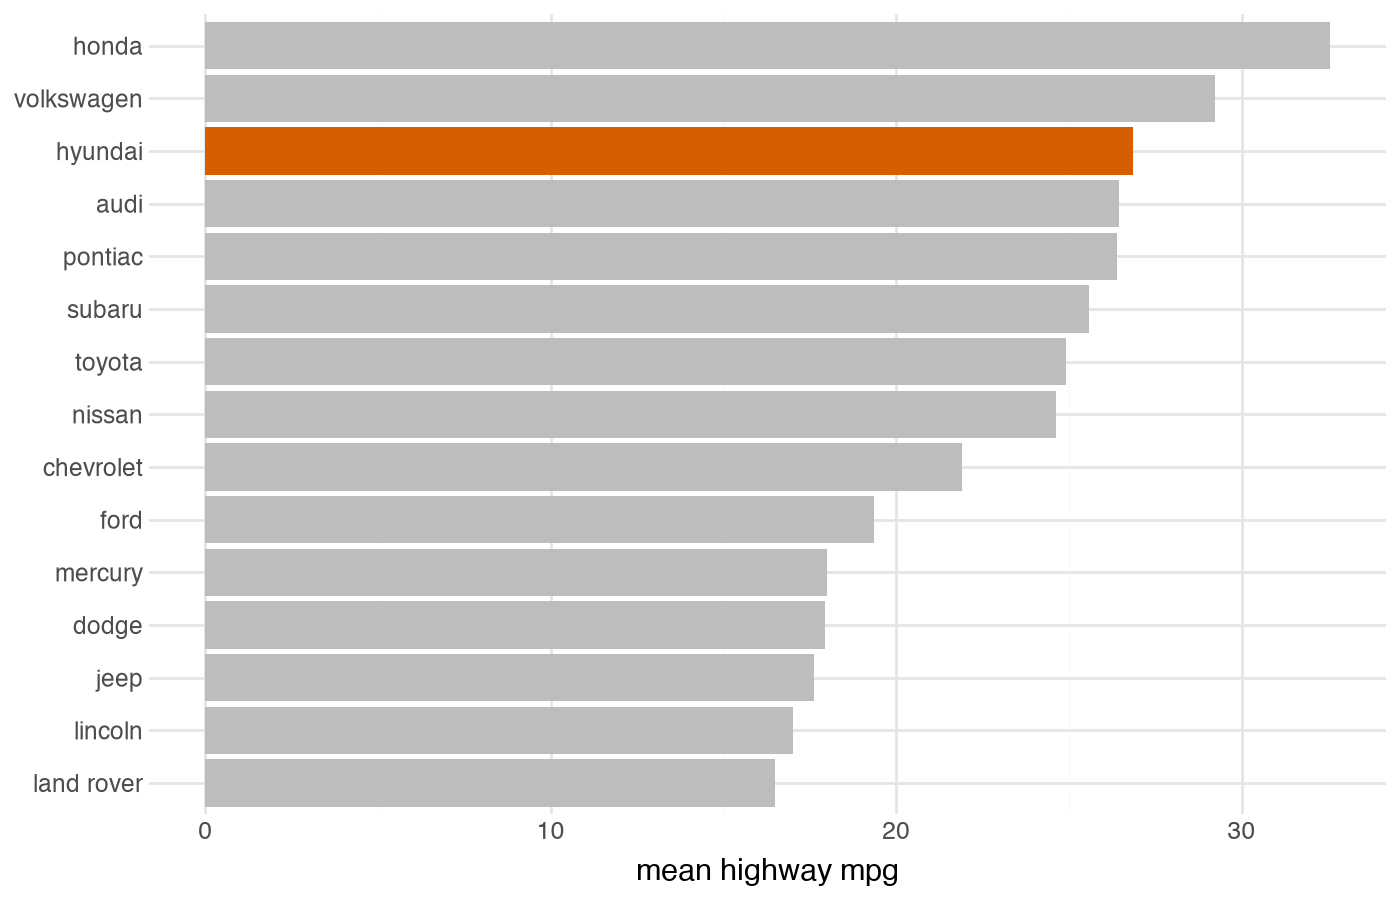

In [14]:
maker["highlight"] = np.where(maker["manufacturer"] == "hyundai", "hyundai", "other")   # TODO

(
    ggplot(maker, aes(x="reorder(manufacturer, hwy)", y="hwy", fill="highlight"))
    + geom_col()
    + coord_flip()
    + scale_fill_manual(values={"hyundai": "#D55E00", "other": "#BDBDBD"}, guide=None)        # TODO: 강조색 / 기본색
    + labs(x="", y="mean highway mpg")
)

### 문제 3-3 (빈칸) — 순차적 스케일 히트맵
슬라이드 39~40의 인터넷 사용자 히트맵처럼, 텍사스 46개 도시의 **연도별 주택 가격 중위값**을 히트맵으로 그립니다.
- 도시 순서는 **중위값이 처음으로 $150,000을 넘긴 연도** 기준입니다. 슬라이드 40과 같은 방식이에요.
- 값의 크기를 표현하므로 **순차적** 컬러맵 `magma`를 사용하세요.

In [15]:
tx = (
    txhousing.dropna(subset=["median"])
    .query("year <= 2014")
    .groupby(["city", "year"], as_index=False, observed=True)["median"].mean()
)

# 처음으로 $150,000을 넘긴 연도 (끝까지 못 넘기면 2100) → 빨리 넘긴 도시가 위로 오도록 정렬
first_year = (
    tx[tx["median"] >= 150_000].groupby("city", observed=True)["year"].min()
    .reindex(tx["city"].unique()).fillna(2100)
)
last_value = tx[tx["year"] == 2014].set_index("city")["median"].reindex(first_year.index)
order = (
    pd.DataFrame({"first": first_year, "last": last_value})
    .sort_values(["first", "last"], ascending=[False, True]).index
)
tx["city"] = pd.Categorical(tx["city"], categories=order)

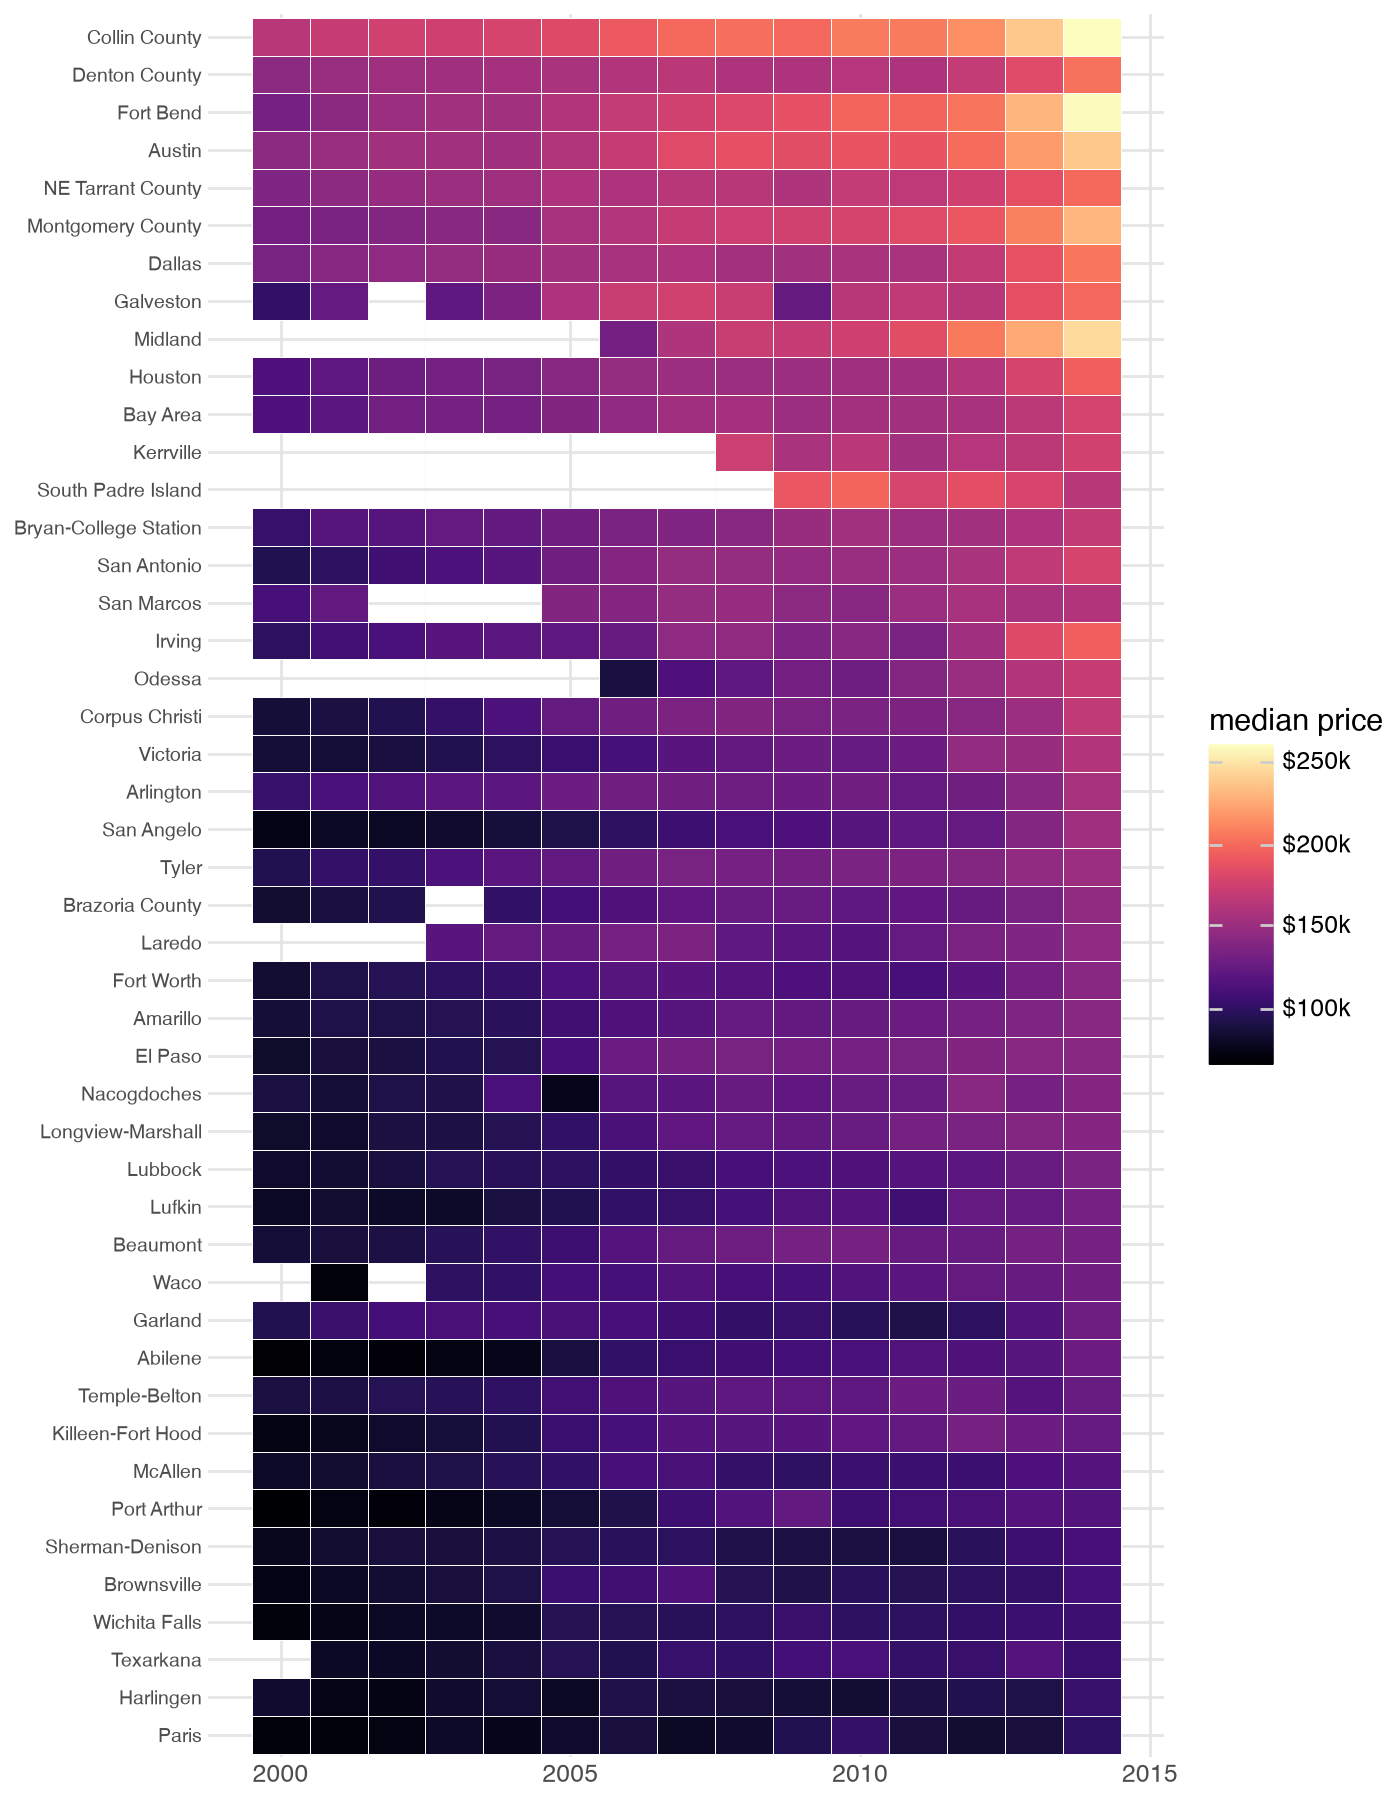

In [16]:
(
    ggplot(tx, aes(x="year", y="city", fill="median"))       # TODO: 색으로 표현할 값
    + geom_tile(color="white", size=0.2)                       # TODO: 히트맵을 그리는 geom
    + scale_fill_cmap("magma", labels=lambda v: [f"${x/1000:.0f}k" for x in v])   # TODO: 순차적 컬러맵
    + labs(x="", y="", fill="median price")
    + theme(figure_size=(7, 9), axis_text_y=element_text(size=7))
)

### 문제 3-4 (빈칸) — 발산형 스케일
이번에는 각 도시의 **연도별 월평균 주택 거래량(sales)이 그 도시의 전체 평균보다 몇 % 많거나 적은지** 표현합니다.
값에 **양수와 음수가 섞여 있고 0이 기준점**이므로, 0을 중립색(흰색)에 맞춘 발산형 스케일을 사용하세요.

In [17]:
sales = (
    txhousing.dropna(subset=["sales"])
    .query("year <= 2014")
    .groupby(["city", "year"], as_index=False, observed=True)["sales"].mean()   # 월평균 (기록이 일부 달만 있는 해도 공정하게 비교)
)
sales["pct_diff"] = sales.groupby("city")["sales"].transform(lambda s: (s / s.mean() - 1) * 100)
sales["city"] = pd.Categorical(sales["city"], categories=order)   # 3-3과 같은 도시 순서

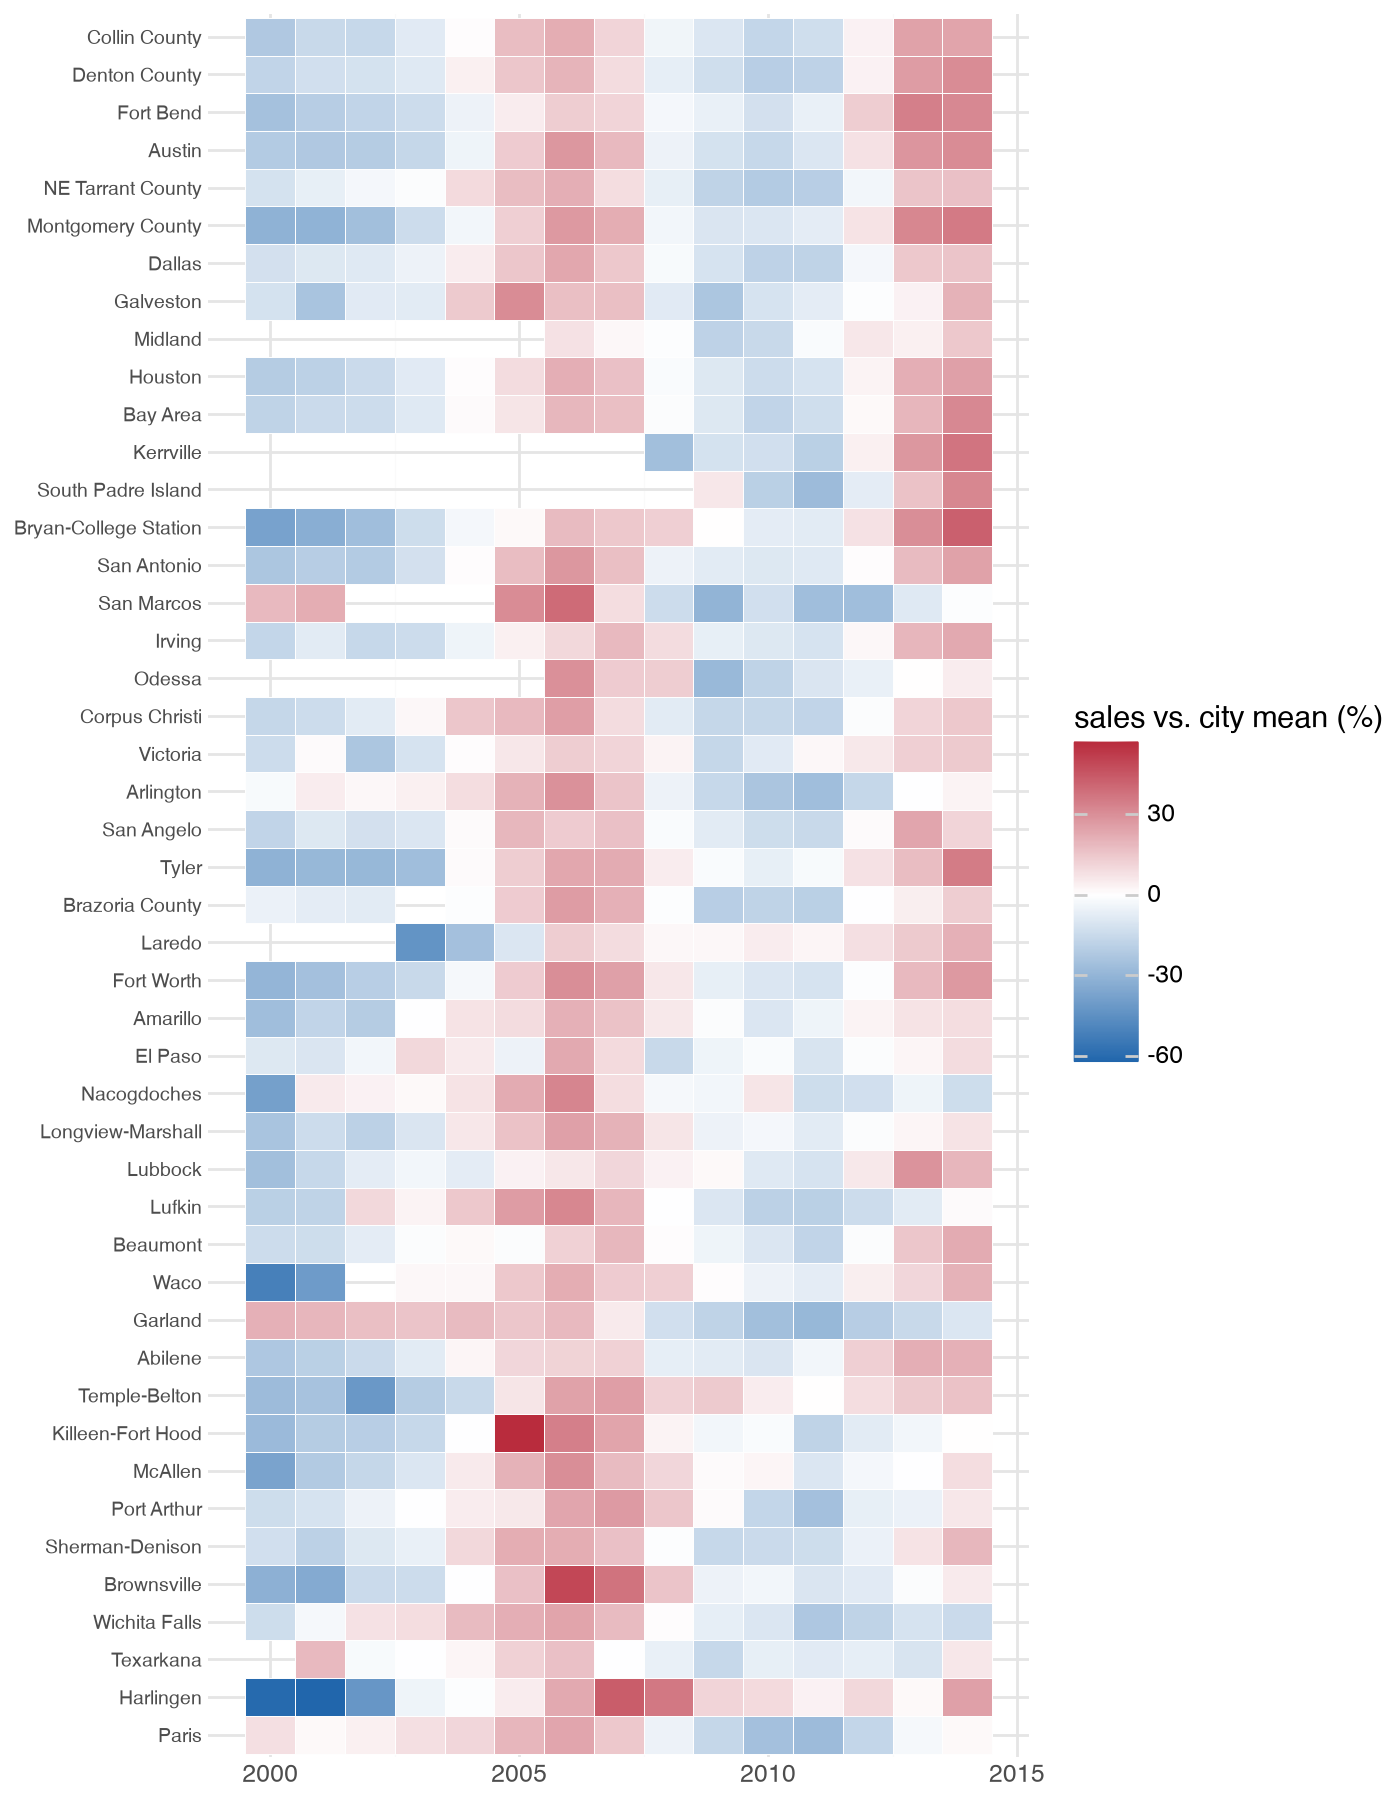

In [18]:
(
    ggplot(sales, aes(x="year", y="city", fill="pct_diff"))
    + geom_tile(color="white", size=0.2)
    + scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B", midpoint=0)   # TODO
    + labs(x="", y="", fill="sales vs. city mean (%)")
    + theme(figure_size=(7, 9), axis_text_y=element_text(size=7))
)

### 문제 3-5 📝
1. 3-3에는 순차적 스케일을, 3-4에는 발산형 스케일을 쓴 이유를 설명하세요.
2. 3-4 히트맵에서 텍사스 주택 시장에 대해 읽어낼 수 있는 패턴 하나를 적어 보세요.

**✍️ 답:**
1. 3-3의 주택 가격은 낮음에서 높음으로 정렬을 하므로 순차적 스케일이 적합하고, 3-4는 0을 기준으로 증감의 방향과 크기를 나타내기에 0을 흰색으로 둔 발산형 스케일이 적합하다.
2. 거의 대부분의 도시에서 처음에는 파랗게 나타나다 2005~2006년에는 평균보다 거래량이 많아 붉게, 2010~2011년에는 평균보다 적어 다시 푸르게 나타나다 2013~2014년에 다시 붉어지는 패턴을 보인다. 

## 4. 수량 데이터의 시각화

### 문제 4-1 🔧 고치기 — 막대도표
아래는 2014년 주택 거래량 상위 12개 도시를 그린 그래프입니다. 슬라이드 30에서 *조악함*으로 지적한 문제가 있습니다.
**정렬된 가로 막대 그래프**로 고치세요.

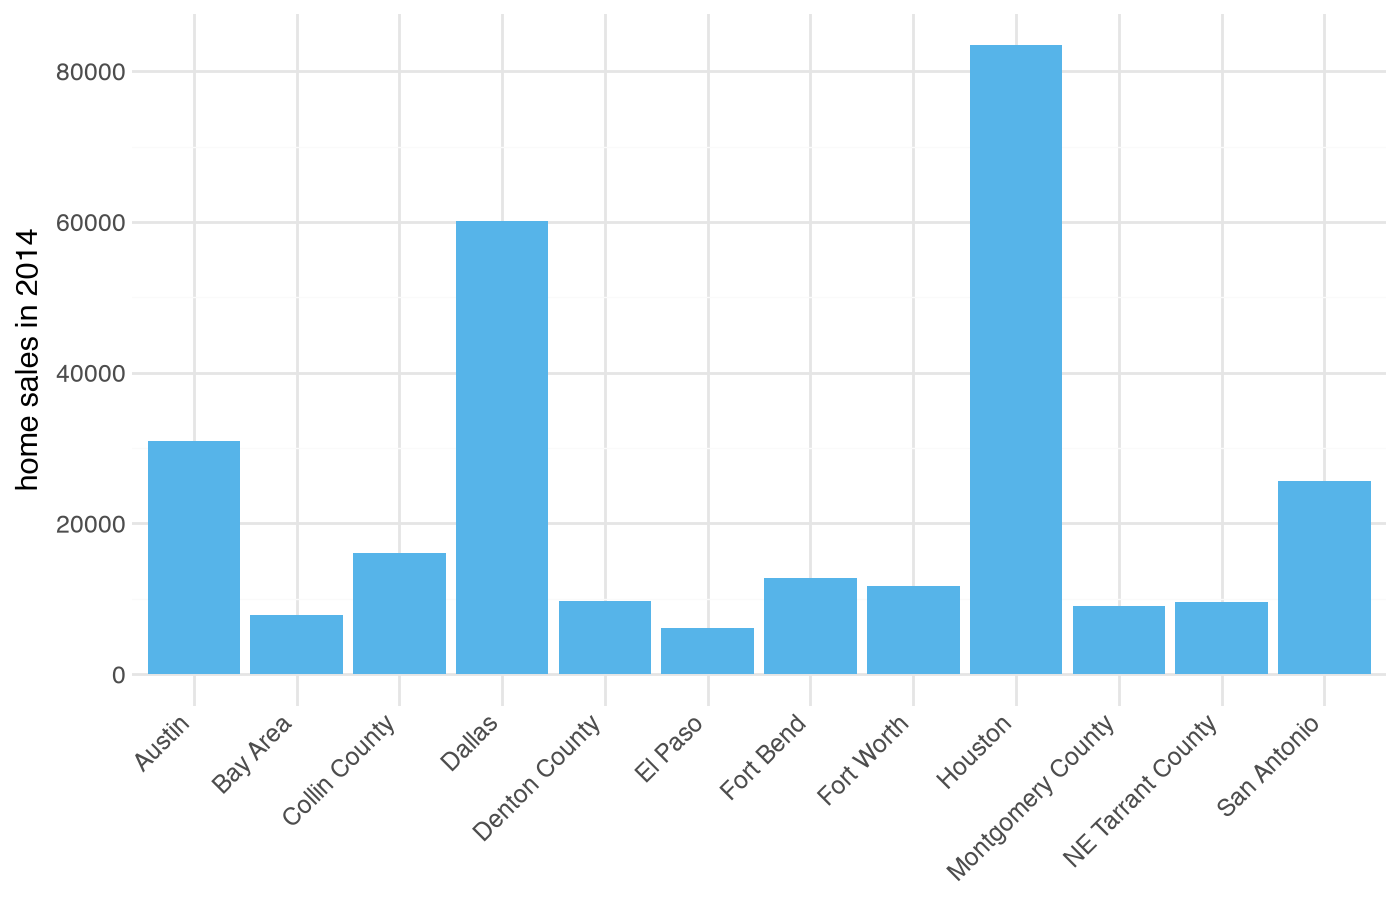

In [19]:
top12 = (
    txhousing.query("year == 2014").groupby("city", as_index=False)["sales"].sum()
    .nlargest(12, "sales")
    .sample(frac=1, random_state=7)   # 일부러 순서를 섞음
)

# ❌ 조악한 그래프 (그대로 두세요)
(
    ggplot(top12, aes(x="city", y="sales"))
    + geom_col(fill="#56B4E9")
    + theme(axis_text_x=element_text(rotation=45, ha="right"))
    + labs(x="", y="home sales in 2014")
)

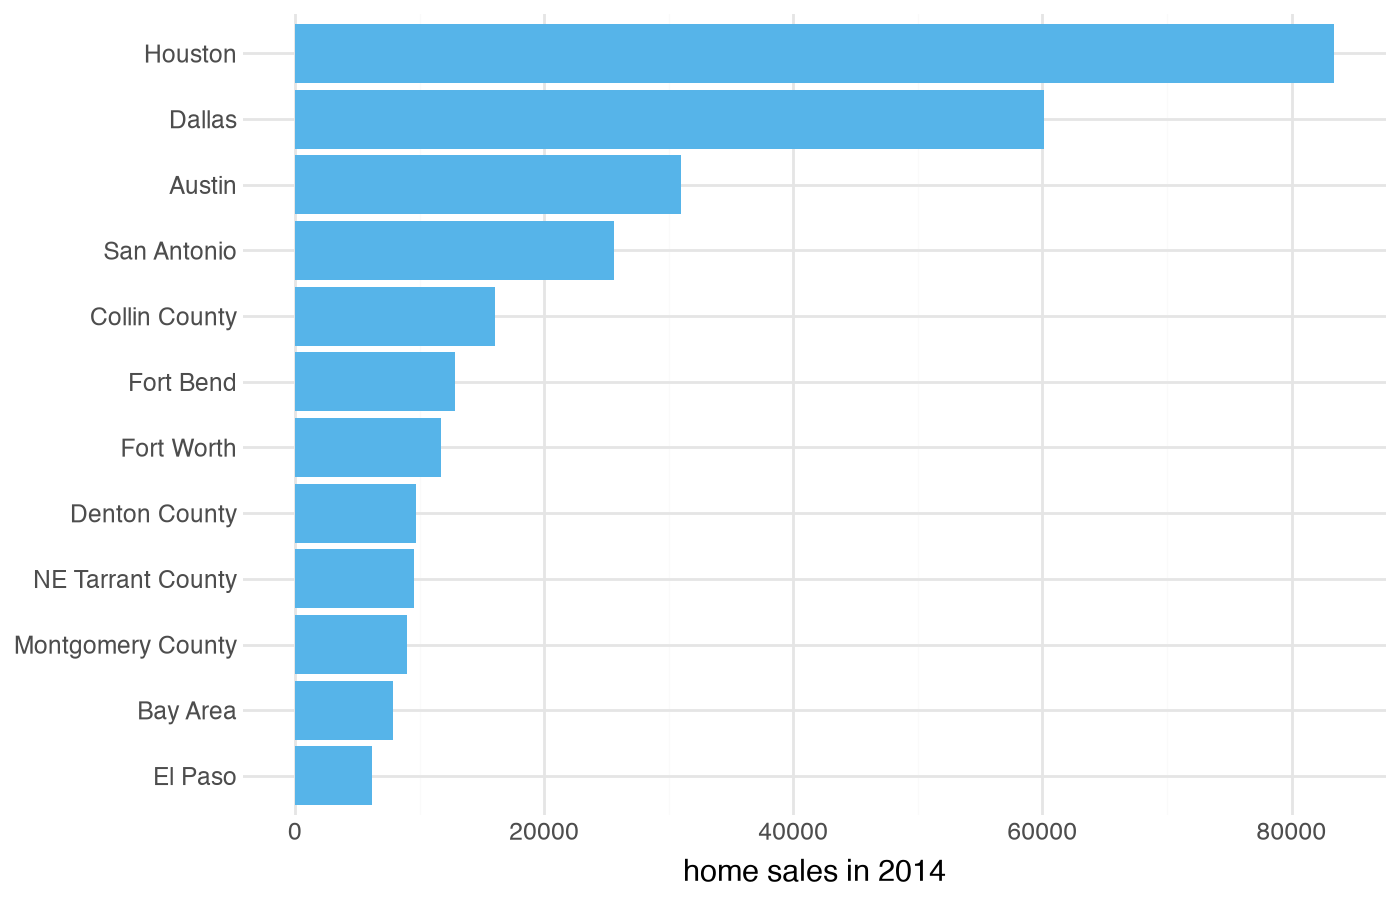

In [ ]:
# ✅ 고친 그래프를 작성하세요
# 거래량으로 정렬하고 가로로 배치하면 도시 이름과 순위를 읽기 쉬워진다.
(
    ggplot(top12, aes(x="reorder(city, sales)", y="sales"))
    + geom_col(fill="#56B4E9")
    + coord_flip()
    + labs(x="", y="home sales in 2014")
)

### 문제 4-2 🔧 고치기 — 순서가 있는 범주
아래는 휴스턴의 **월별 평균 주택 거래량**입니다. 4-1과 똑같이 값 순서로 정렬했는데, 슬라이드 32에 따르면 이번에는 오히려 *모호한* 그래프가 됩니다.
올바른 순서로 고치세요.

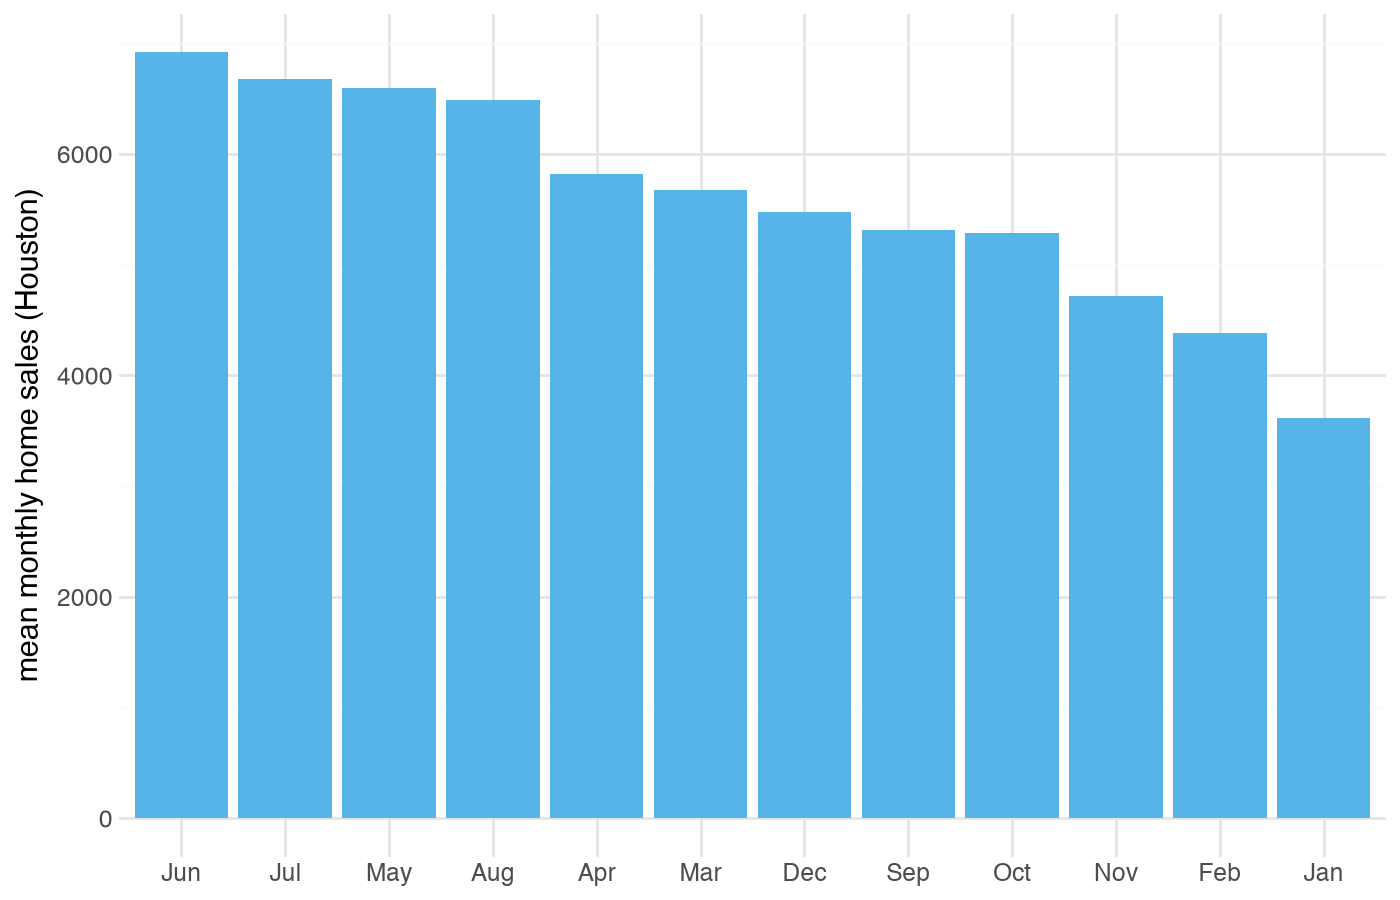

In [21]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

houston = txhousing.query("city == 'Houston'").groupby("month", as_index=False)["sales"].mean()
houston["month_name"] = [MONTHS[m - 1] for m in houston["month"]]

# ❌ 모호한 그래프 (그대로 두세요)
(
    ggplot(houston, aes(x="reorder(month_name, -sales)", y="sales"))
    + geom_col(fill="#56B4E9")
    + labs(x="", y="mean monthly home sales (Houston)")
)

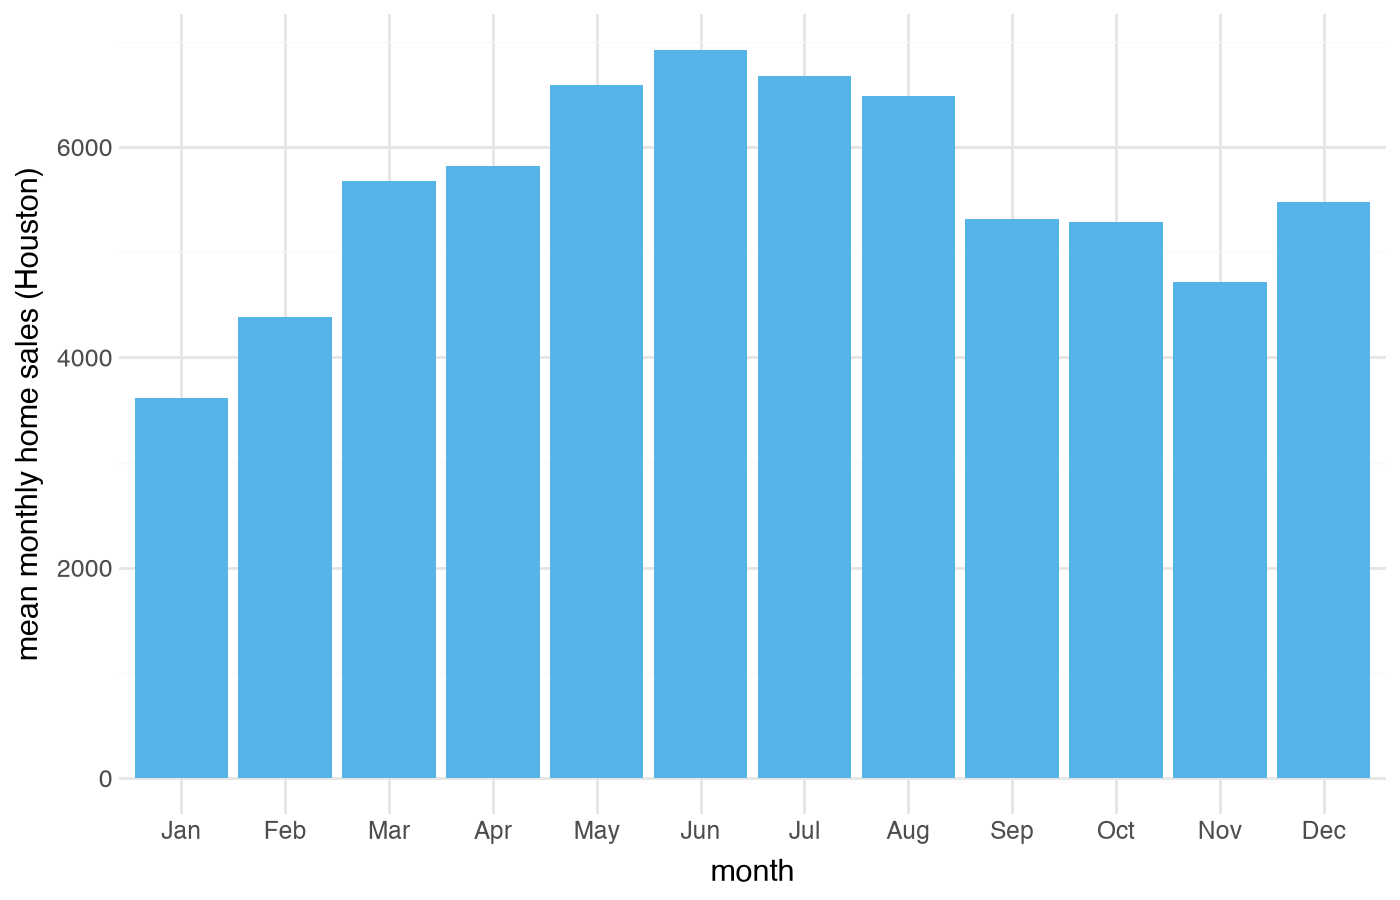

In [ ]:
# ✅ 고친 그래프를 작성하세요 (힌트: pd.Categorical(..., categories=MONTHS, ordered=True))
# 월은 순서가 있는 범주이므로 거래량이 아닌 달력 순서를 유지한다.
houston["month_name"] = pd.Categorical(houston["month_name"], categories=MONTHS, ordered=True)
(
    ggplot(houston, aes(x="month_name", y="sales"))
    + geom_col(fill="#56B4E9")
    + labs(x="month", y="mean monthly home sales (Houston)")
)

### 문제 4-3 (빈칸) — 묶은 막대 vs 누적 막대
슬라이드 36의 **타이타닉 객실 등급별 승객 수**입니다. 같은 데이터를 두 가지 방법으로 그려 보세요.

In [23]:
titanic = pd.DataFrame({
    "pclass": ["1st", "1st", "2nd", "2nd", "3rd", "3rd"],
    "sex":    ["female", "male"] * 3,
    "count":  [143, 179, 107, 172, 212, 499],
})
titanic

,pclass,sex,count
0,1st,female,143
1,1st,male,179
2,2nd,female,107
3,2nd,male,172
4,3rd,female,212
5,3rd,male,499


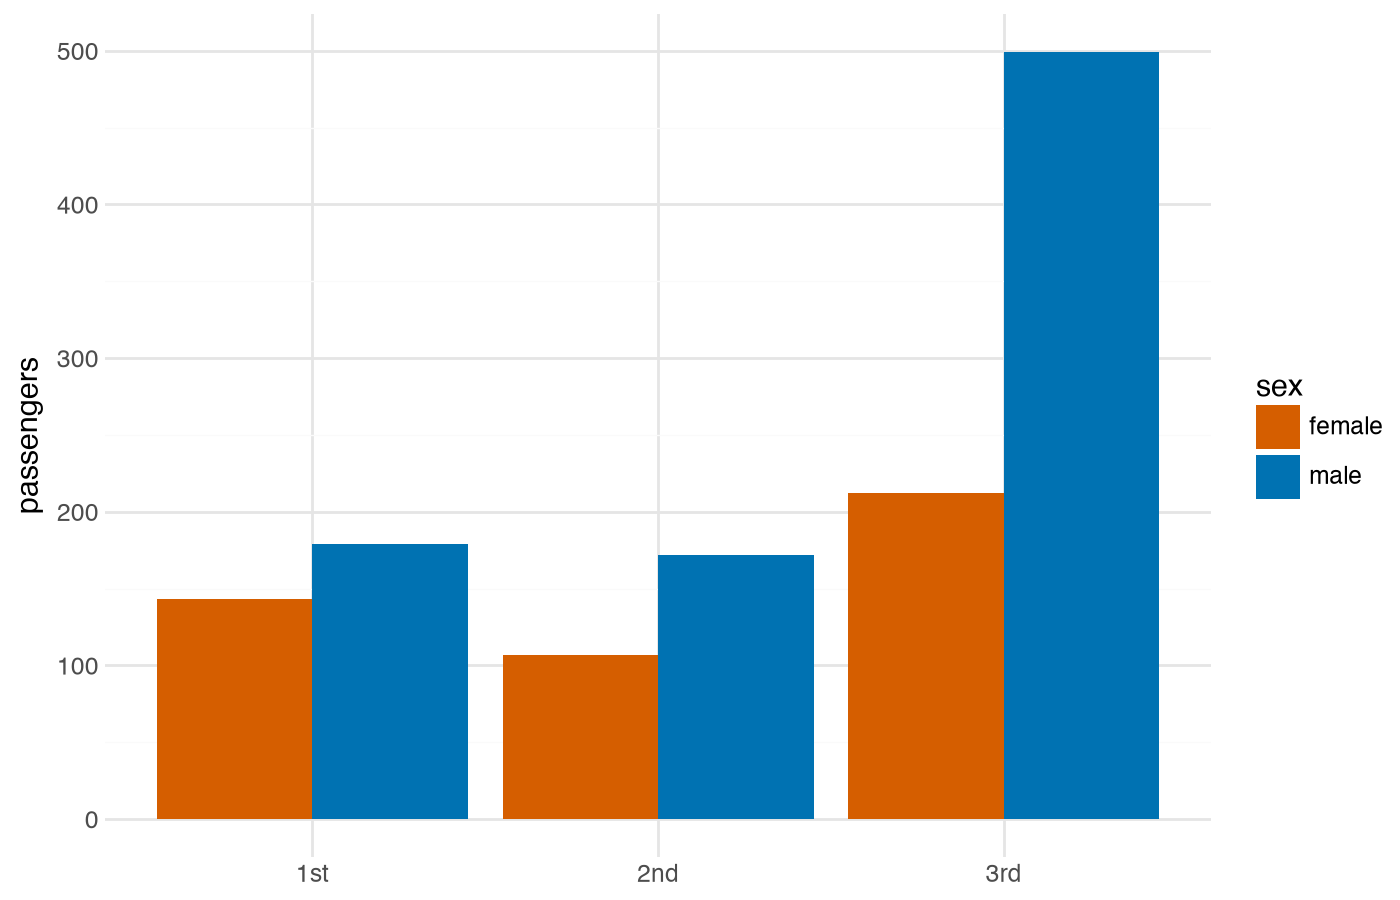

In [24]:
# (a) 묶은 막대: 성별을 나란히
(
    ggplot(titanic, aes(x="pclass", y="count", fill="sex"))
    + geom_col(position="dodge")                          # TODO
    + scale_fill_manual(values=["#D55E00", "#0072B2"])
    + labs(x="", y="passengers")
)

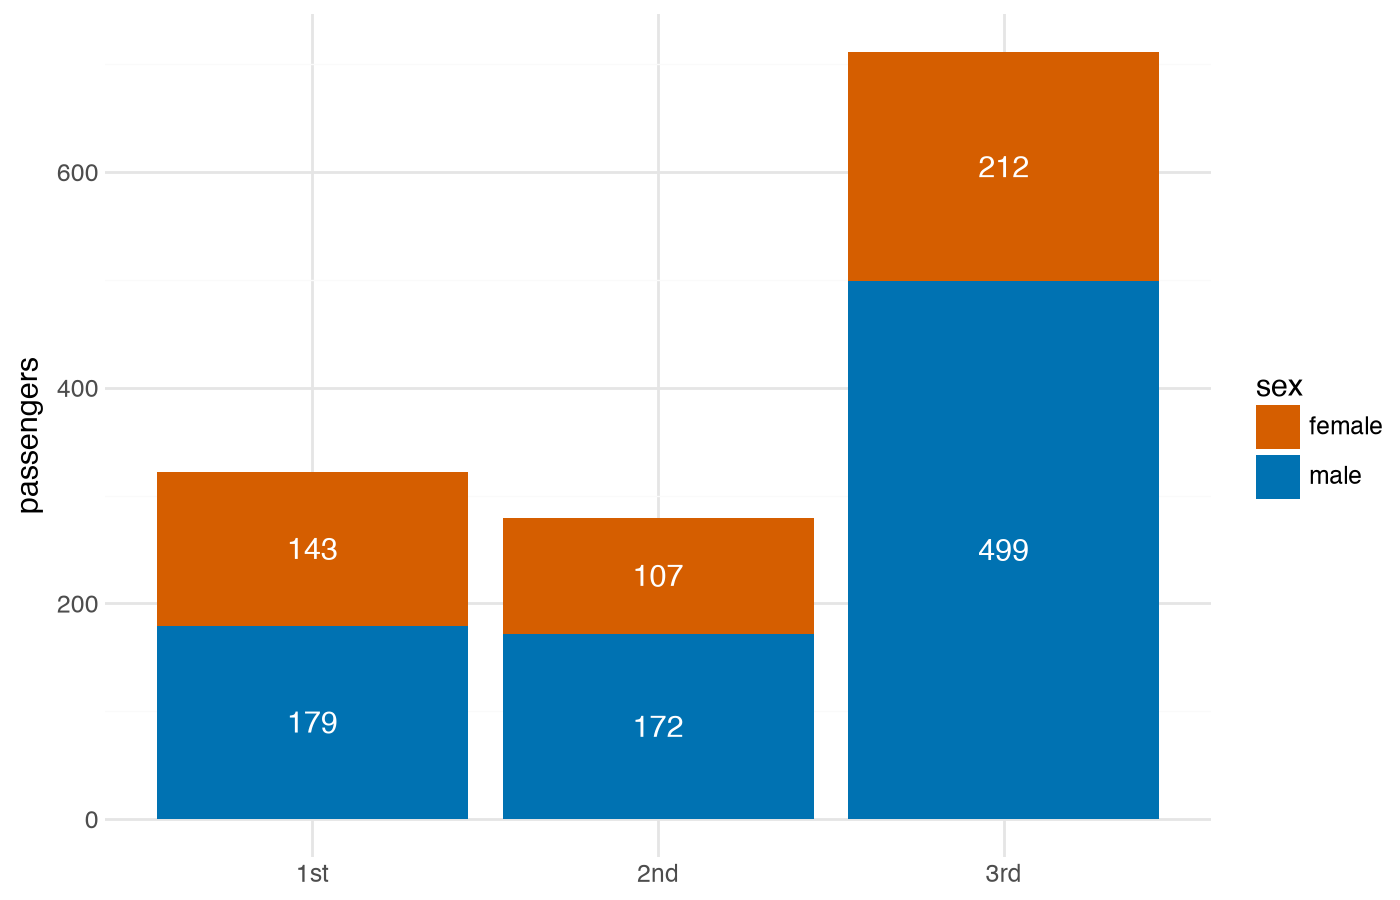

In [25]:
# (b) 누적 막대: 성별을 위로 쌓기 + 막대 안에 숫자 표시
(
    ggplot(titanic, aes(x="pclass", y="count", fill="sex"))
    + geom_col(position="stack")                          # TODO
    + geom_text(aes(label="count"), position=position_stack(vjust=0.5), color="white")
    + scale_fill_manual(values=["#D55E00", "#0072B2"])
    + labs(x="", y="passengers")
)

### 문제 4-4 📝
(a)와 (b) 중 **"3등실에 탄 승객이 전체적으로 가장 많다"** 는 사실을 보여주기에 더 좋은 그래프는 무엇이고, 그 이유는 무엇인가요?
반대로 **"각 등급에서 남성이 여성보다 몇 명 더 많은가"** 를 비교하기에는 어느 쪽이 나은가요?

**✍️ 답:** 전체 승객 수를 (b)의 누적 막대 자체의 높이로 바로 비교할 수 있어 (b)가 더 적절하다. 반면 등급별 남녀 차이는 두 막대가 동일한 0 기준선에서 시작하므로 (a)가 더 적절하다.

### 문제 4-5 🔧 고치기 — 점 도표
2014년 텍사스 도시별 **주택 가격 중위값**을 막대로 그렸더니, 슬라이드 38처럼 막대 길이가 거의 비슷해 차이가 두드러지지 않습니다.
정렬된 **점 도표**로 고치세요.

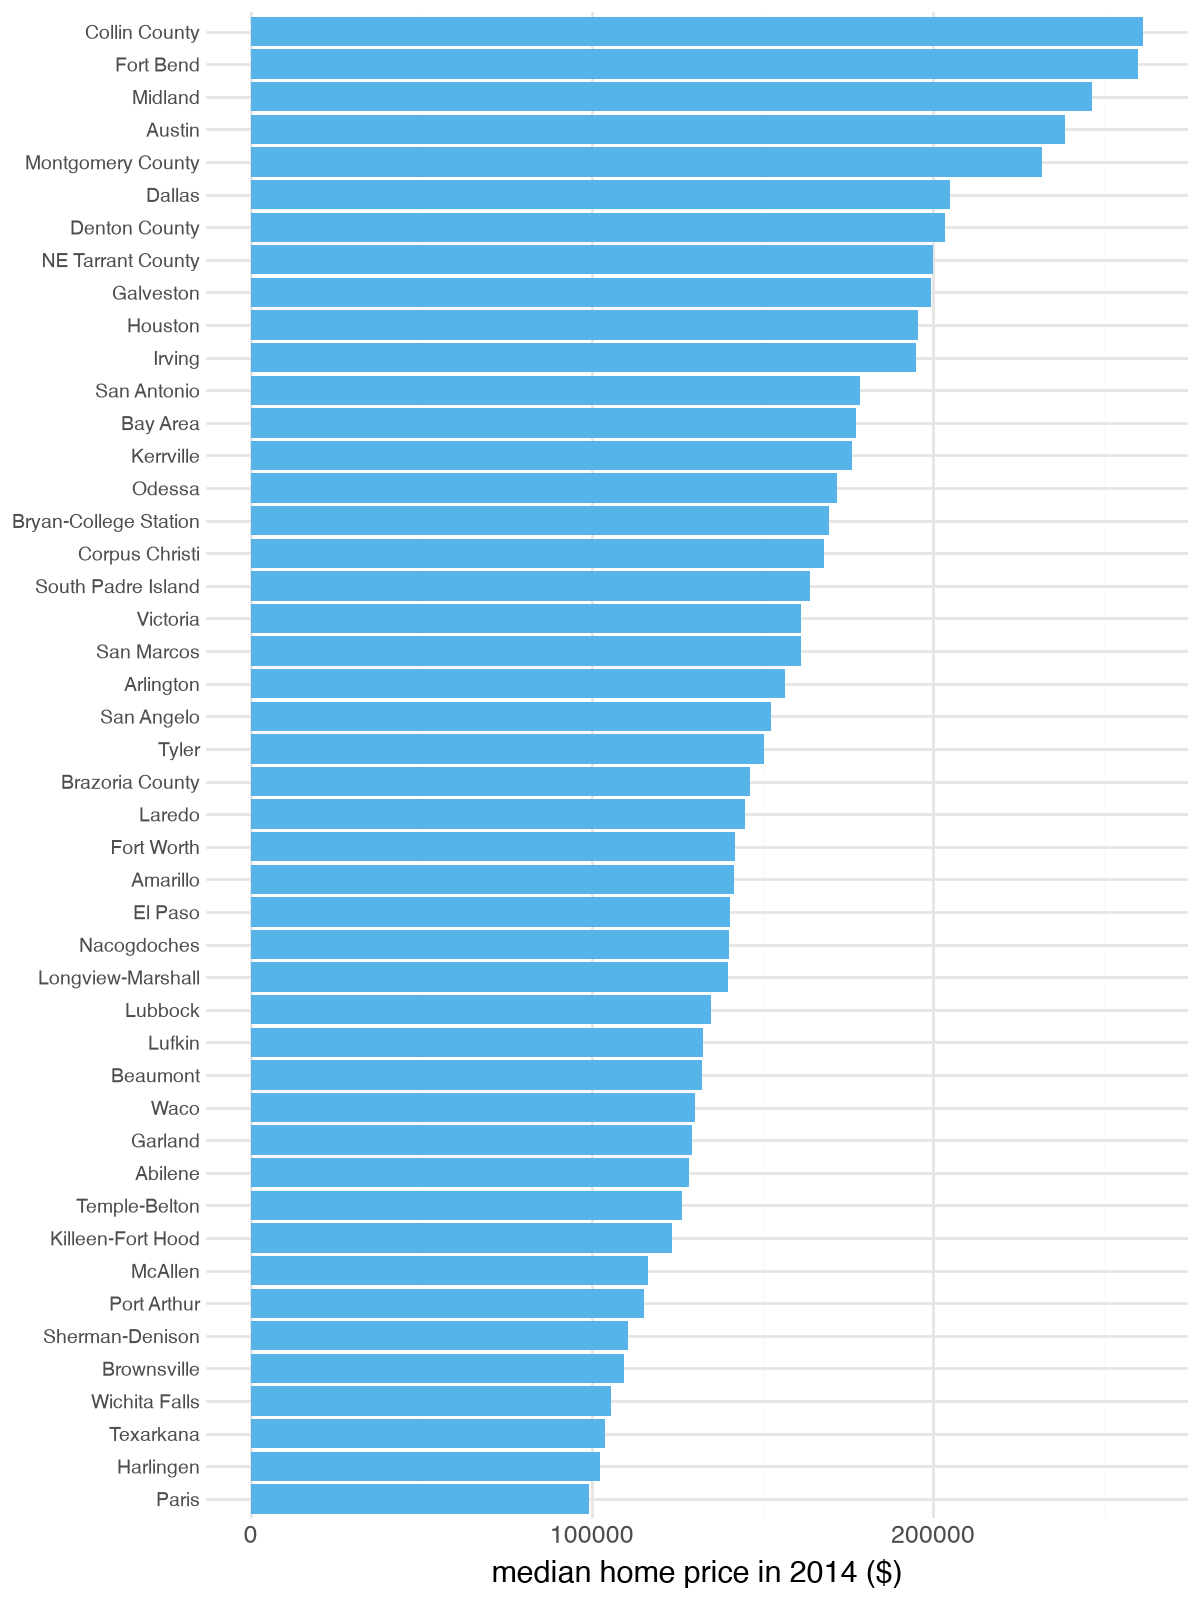

In [26]:
price14 = txhousing.query("year == 2014").groupby("city", as_index=False)["median"].mean().dropna()

# ❌ 모호한 그래프 (그대로 두세요)
(
    ggplot(price14, aes(x="reorder(city, median)", y="median"))
    + geom_col(fill="#56B4E9")
    + coord_flip()
    + labs(x="", y="median home price in 2014 ($)")
    + theme(figure_size=(6, 8), axis_text_y=element_text(size=7))
)

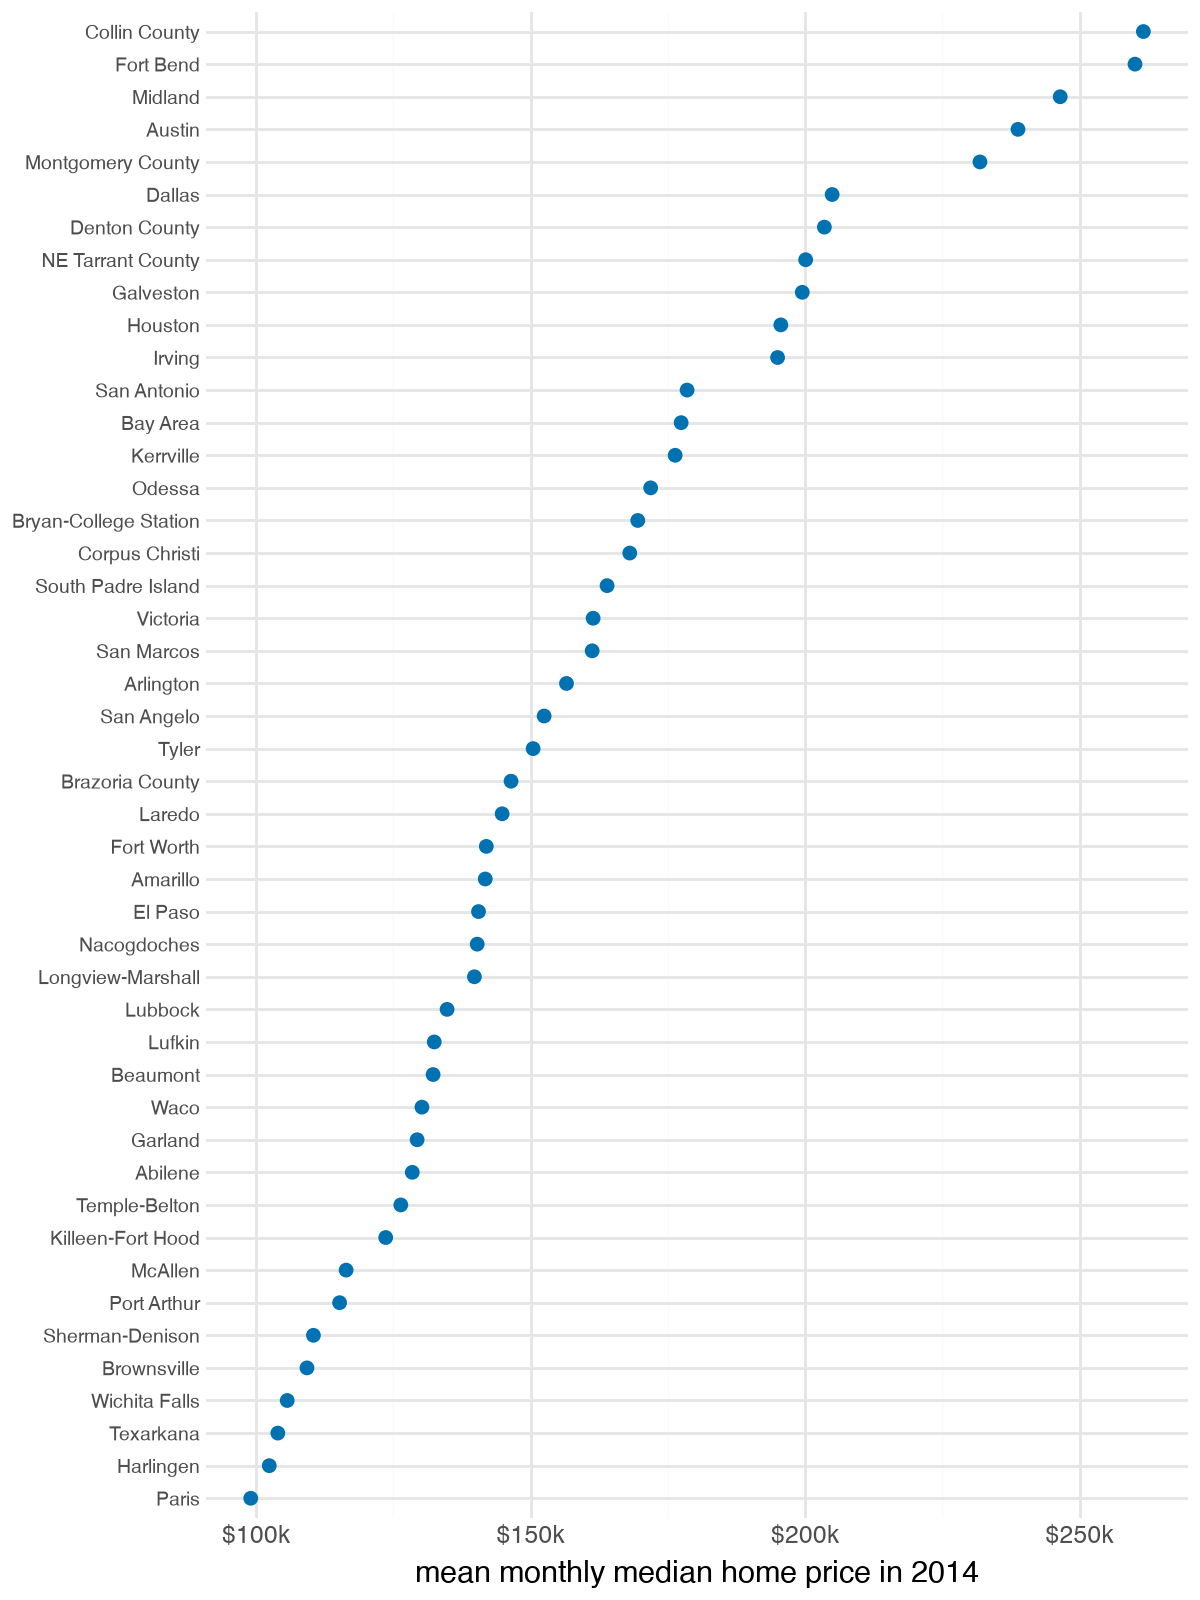

In [27]:
# ✅ 고친 그래프를 작성하세요
(
    ggplot(price14, aes(x="median", y="reorder(city, median)"))
    + geom_point(color="#0072B2", size=2)
    + scale_x_continuous(labels=lambda v: [f"${x/1000:.0f}k" for x in v])
    + labs(x="mean monthly median home price in 2014", y="")
    + theme(figure_size=(6, 8), axis_text_y=element_text(size=7))
)

### 문제 4-6 📝
막대도표에서는 **y축을 0이 아닌 곳에서 시작하면 안 되는데**, 점 도표에서는 괜찮은 이유는 무엇일까요?

**✍️ 답:** 막대도표는 0을 기준으로 해서 막대의 길이로 표현하므로 축을 중간에서 자르면 실제 차이가 왜곡되어 표현될 수 있지만 점 도표는 길이가 아니라 같은 기준에서의 위치로 표현하므로 굳이 0이 아닌 곳에서 시작해도 무방하다.

## 5. 분포 데이터의 시각화

`faithful`은 옐로스톤의 Old Faithful 간헐천 데이터이고, `waiting`은 분출 사이의 대기 시간(분)입니다.

### 문제 5-1 (빈칸) — 히스토그램의 구간 폭
구간 폭(`binwidth`)을 **1, 5, 10, 20분**으로 바꿔 가며 히스토그램 4개를 그리세요.

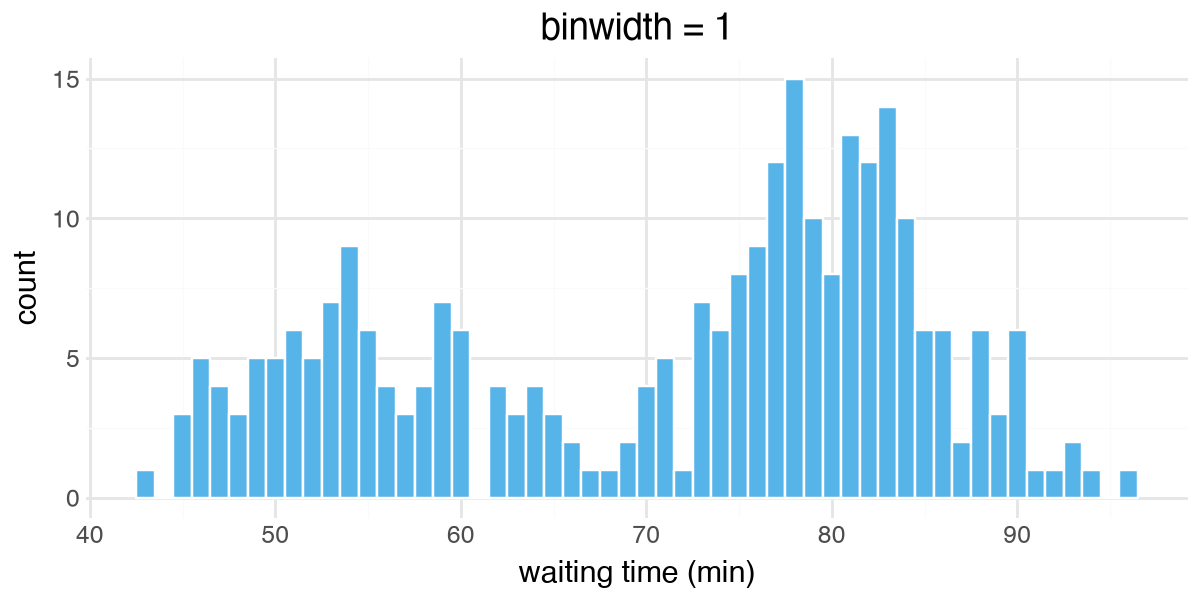

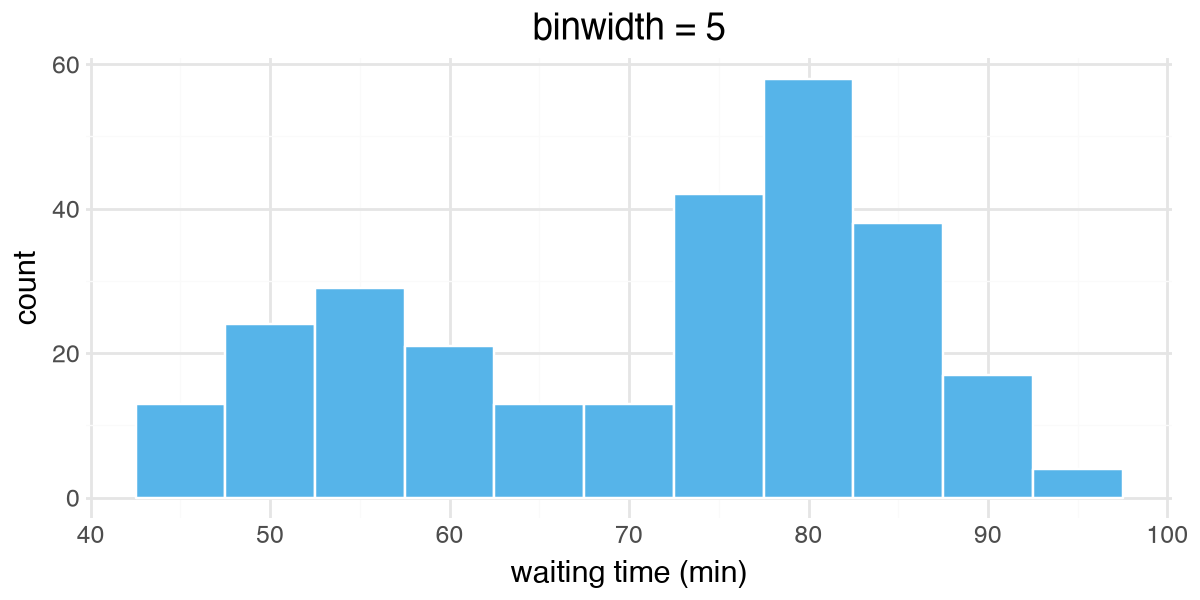

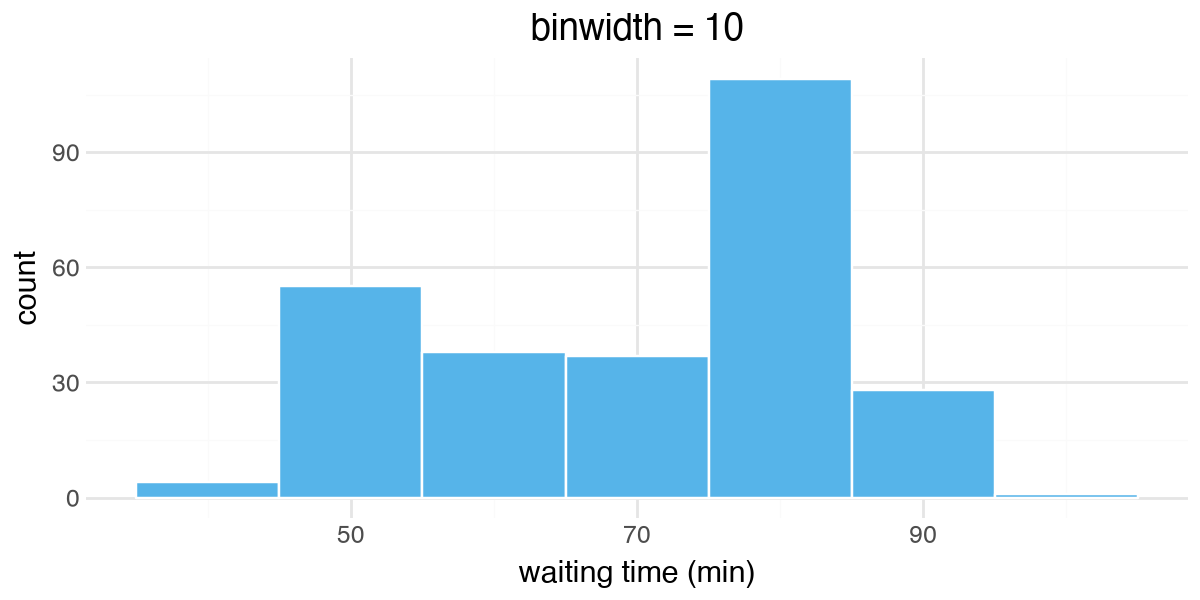

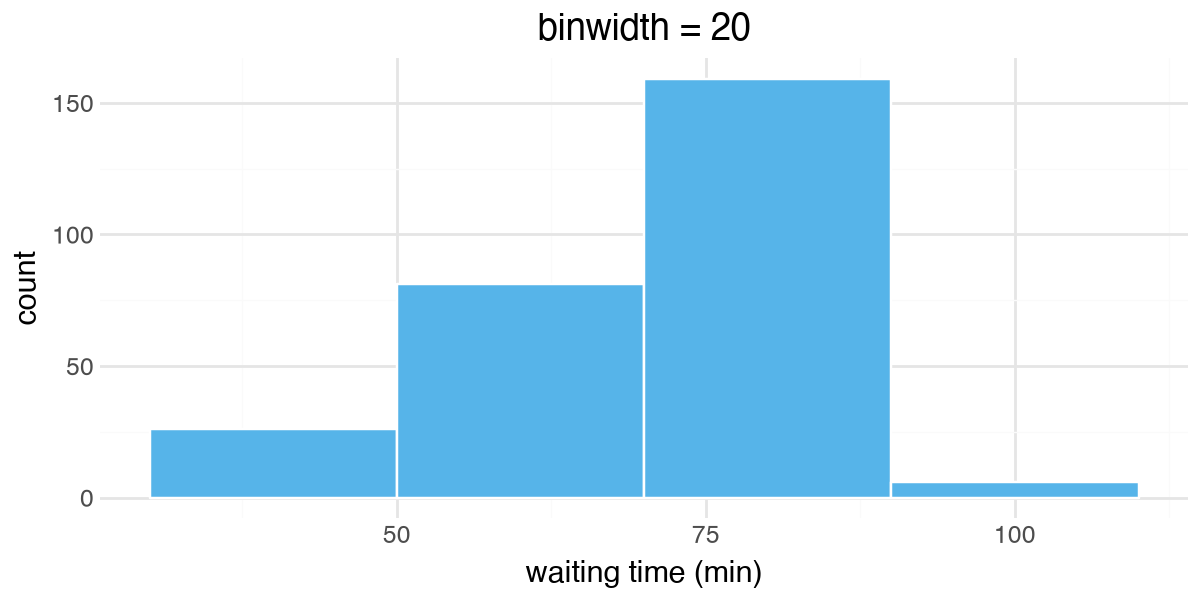

In [28]:
for bw in [1, 5, 10, 20]:
    display(
        ggplot(faithful, aes(x="waiting"))
        + geom_histogram(binwidth=bw, fill="#56B4E9", color="white")   # TODO
        + labs(title=f"binwidth = {bw}", x="waiting time (min)", y="count")
        + theme(figure_size=(6, 3))
    )

### 문제 5-2 (빈칸) — 밀도 도표의 대역폭
`geom_density`의 `adjust`는 기본 대역폭에 곱하는 배수입니다. `adjust`를 **0.2, 1, 3**으로 바꿔 가며 밀도 도표를 그리세요.

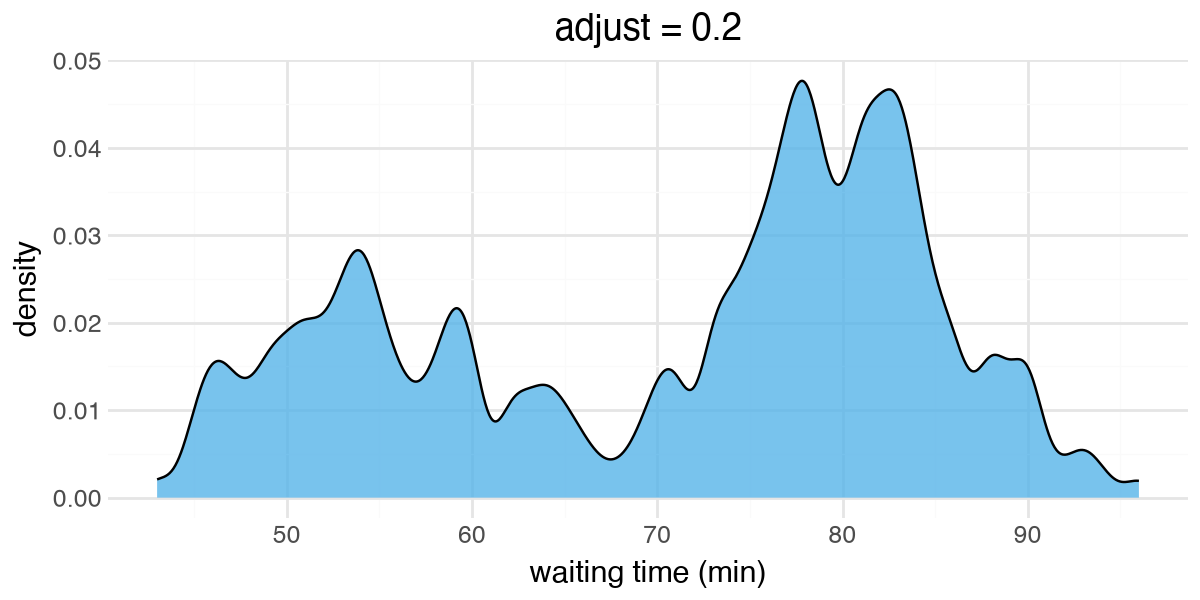

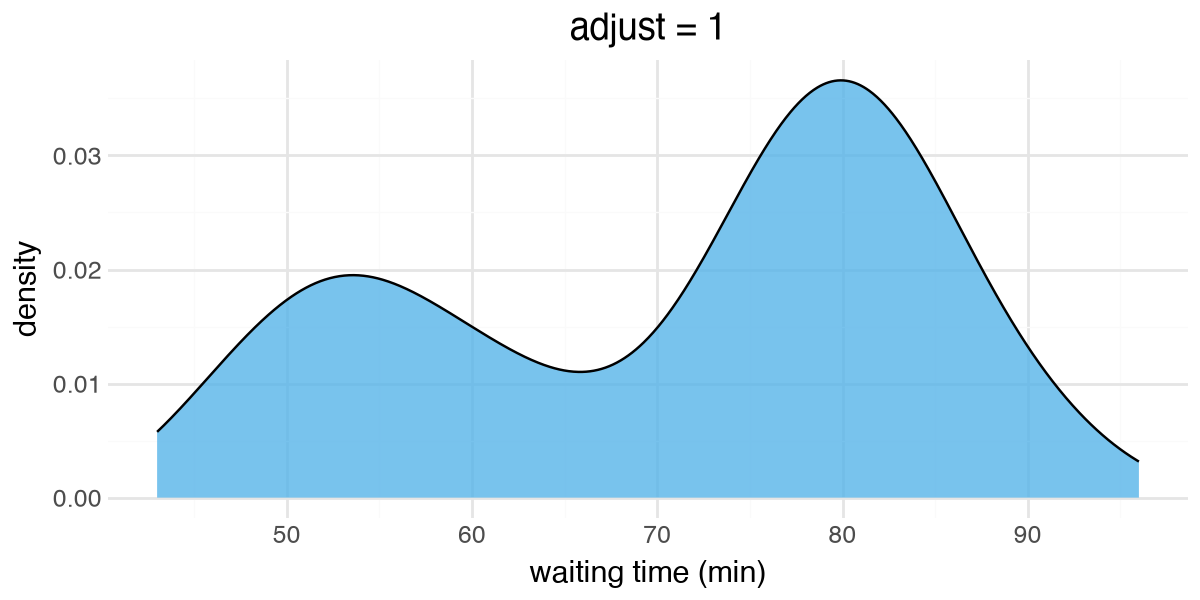

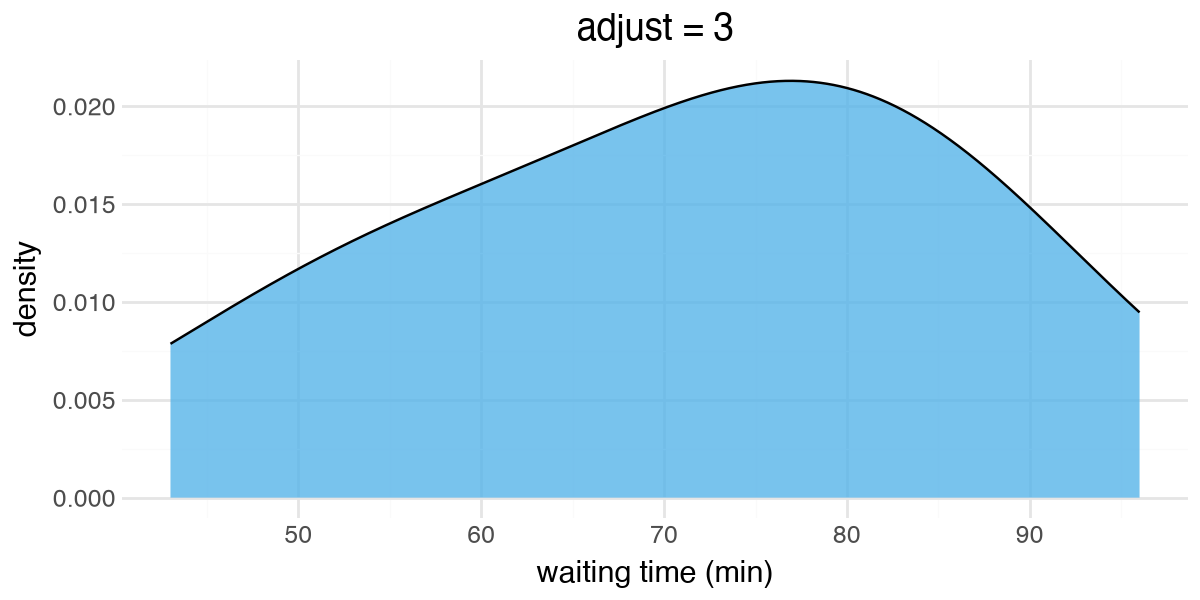

In [29]:
for adj in [0.2, 1, 3]:
    display(
        ggplot(faithful, aes(x="waiting"))
        + geom_density(adjust=adj, fill="#56B4E9", alpha=0.8)    # TODO: 밀도 도표 geom
        + labs(title=f"adjust = {adj}", x="waiting time (min)", y="density")
        + theme(figure_size=(6, 3))
    )

### 문제 5-3 📝
1. 5-1에서 구간 폭이 **너무 좁을 때**와 **너무 넓을 때** 각각 어떤 문제가 생기나요? 특히 binwidth = 20에서 사라지는 중요한 특징은 무엇인가요?
2. 5-2에서 대역폭을 크게 하면 그래프가 어떻게 변하나요? 데이터에 대해 어떤 오해를 할 수 있을까요?

**✍️ 답:** 
1. 구간 폭이 너무 좁으면 작은 표본 변동으로 막대가 들쭉날쭉해 전체 구조를 읽기 어렵고, 너무 넓으면 서로 다른 값들이 한 구간에 합쳐져 세부 구조가 사라진다. `binwidth=20`에서는 50~60 사이의 패턴을 거의 보여주지 못한다는 단점이 있다.
2. 대역폭을 크게 하면 밀도 곡선이 더 매끄러워지지만 과도하게 키우면 두 봉우리가 연결이 되어버려 서로 다른 두 집단을 하나로 오해해버릴 수 있다.

### 문제 5-4 🔧 고치기 — 여러 분포 비교
펭귄 3종의 **몸무게 분포**를 비교하려고 누적 히스토그램을 그렸습니다. 슬라이드 46처럼 막대의 시작 위치가 제각각이라 각 종의 분포를 읽기 어렵습니다.
슬라이드 51처럼 **반투명한 중첩 밀도 도표**로 고치고, 범례 대신 곡선 옆에 **종 이름을 직접 표시**해 보세요.

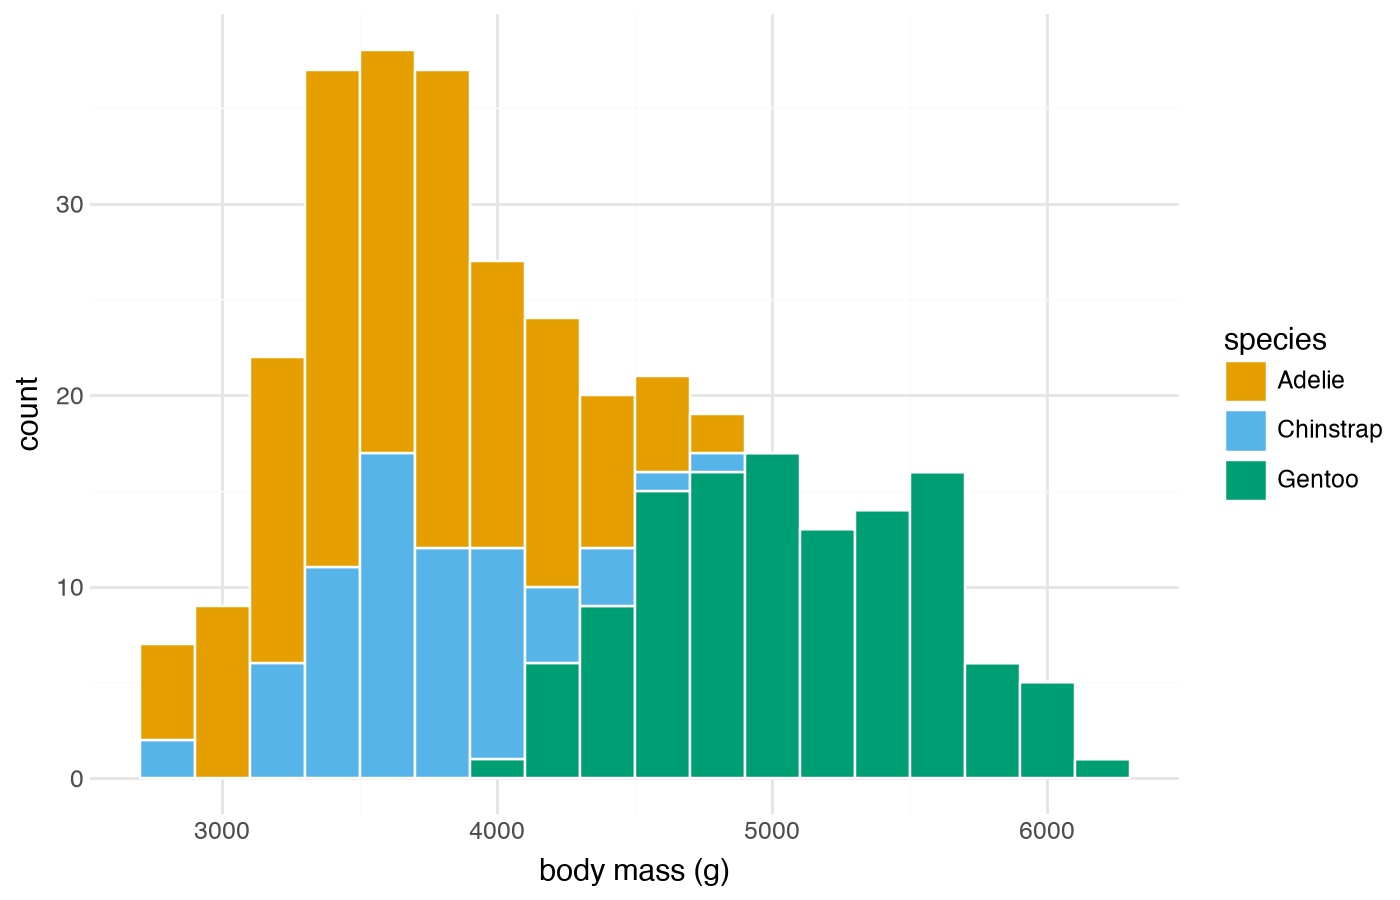

In [30]:
peng = penguins.dropna(subset=["body_mass_g", "sex"])

# ❌ 모호한 그래프 (그대로 두세요)
(
    ggplot(peng, aes(x="body_mass_g", fill="species"))
    + geom_histogram(binwidth=200, position="stack", color="white")
    + scale_fill_manual(values=OKABE_ITO)
    + labs(x="body mass (g)", y="count")
)

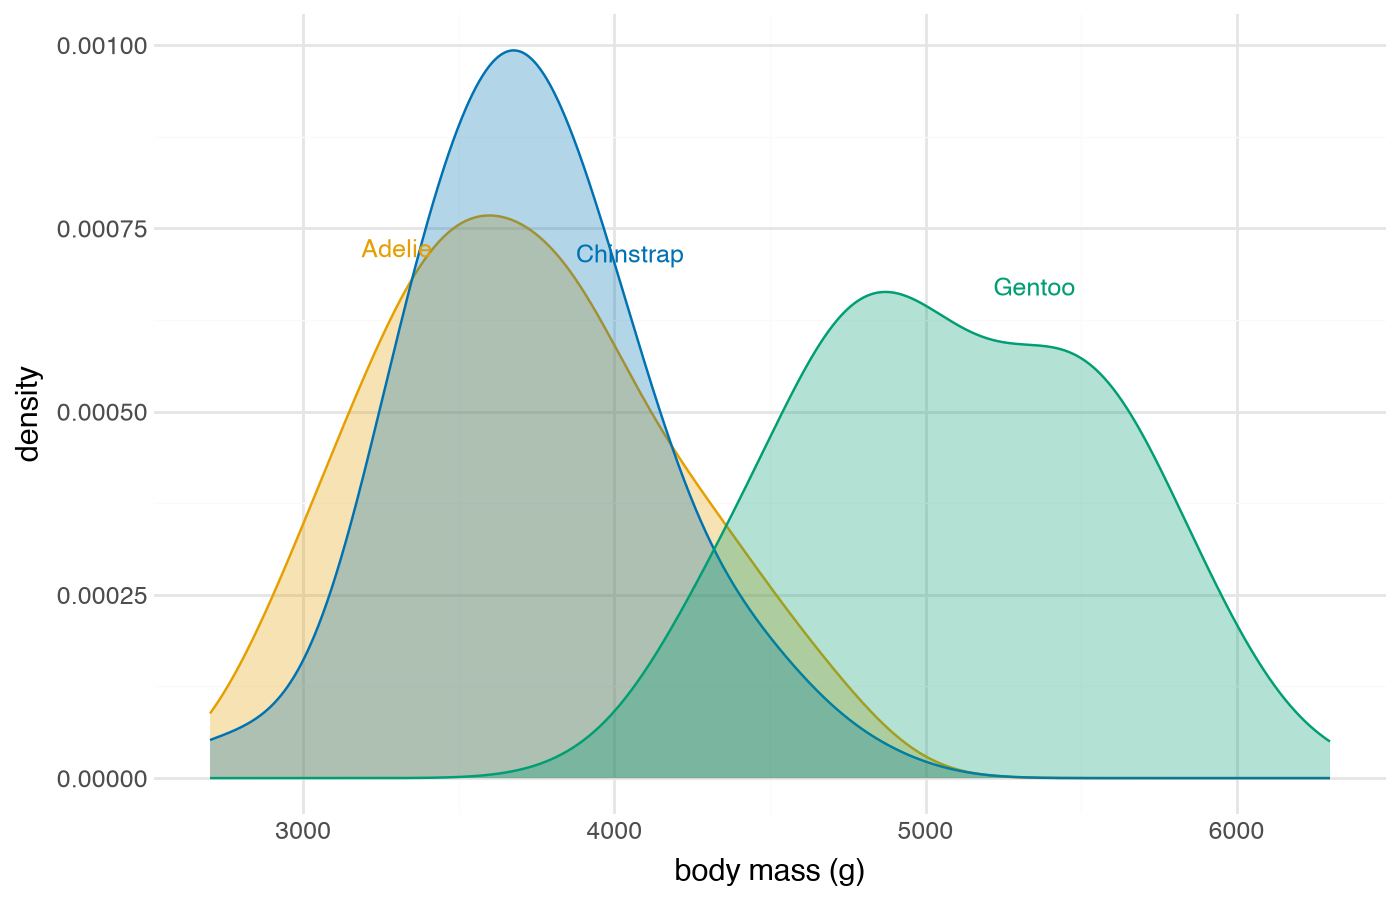

In [31]:
# ✅ 고친 그래프를 작성하세요
# 힌트: geom_density(alpha=...), 직접 라벨은 geom_text(..., data=라벨용 DataFrame)

# 각 종에서 같은 대역폭(200g)을 사용해 평활화 정도를 통일한다.
# 라벨 높이도 동일한 Gaussian KDE 식으로 계산한다.

species_colors = {"Adelie": "#E69F00", "Chinstrap": "#0072B2", "Gentoo": "#009E73"}
label_x = {"Adelie": 3300, "Chinstrap": 4050, "Gentoo": 5350}
label_rows = []
bandwidth = 200
for species, x in label_x.items():
    values = peng.loc[peng["species"] == species, "body_mass_g"].to_numpy()
    z = (x - values) / bandwidth
    density = np.exp(-0.5 * z**2).mean() / (bandwidth * np.sqrt(2 * np.pi))
    label_rows.append({"species": species, "x": x, "y": density + 0.00008})
labels = pd.DataFrame(label_rows)
(
    ggplot(peng, aes(x="body_mass_g", fill="species", color="species"))
    + geom_density(alpha=0.3, bw=bandwidth)
    + geom_text(data=labels, mapping=aes(x="x", y="y", label="species", color="species"),
                inherit_aes=False, size=9, show_legend=False)
    + scale_fill_manual(values=species_colors, guide=None)
    + scale_color_manual(values=species_colors, guide=None)
    + scale_y_continuous(expand=(0.05, 0))
    + labs(x="body mass (g)", y="density")
)

### 문제 5-5 (빈칸) — 전체 분포 대비 비중
슬라이드 49처럼 **수컷과 암컷의 날개 길이 분포**를 따로 그리되, 각 패널 뒤에 **전체 펭귄의 분포를 회색으로** 깔아서 각 성별이 전체에서 차지하는 비중을 보여 주세요.

> 💡 **핵심 아이디어**: 회색 배경 레이어에 `sex` 열이 **없는** 데이터를 주면, `facet_wrap("sex")`이 그 레이어를 모든 패널에 똑같이 그립니다.
> y축은 `after_stat("count")`로 **밀도 × 개수**를 써서, 전체 곡선 아래 면적이 전체 마릿수가 되게 합니다.

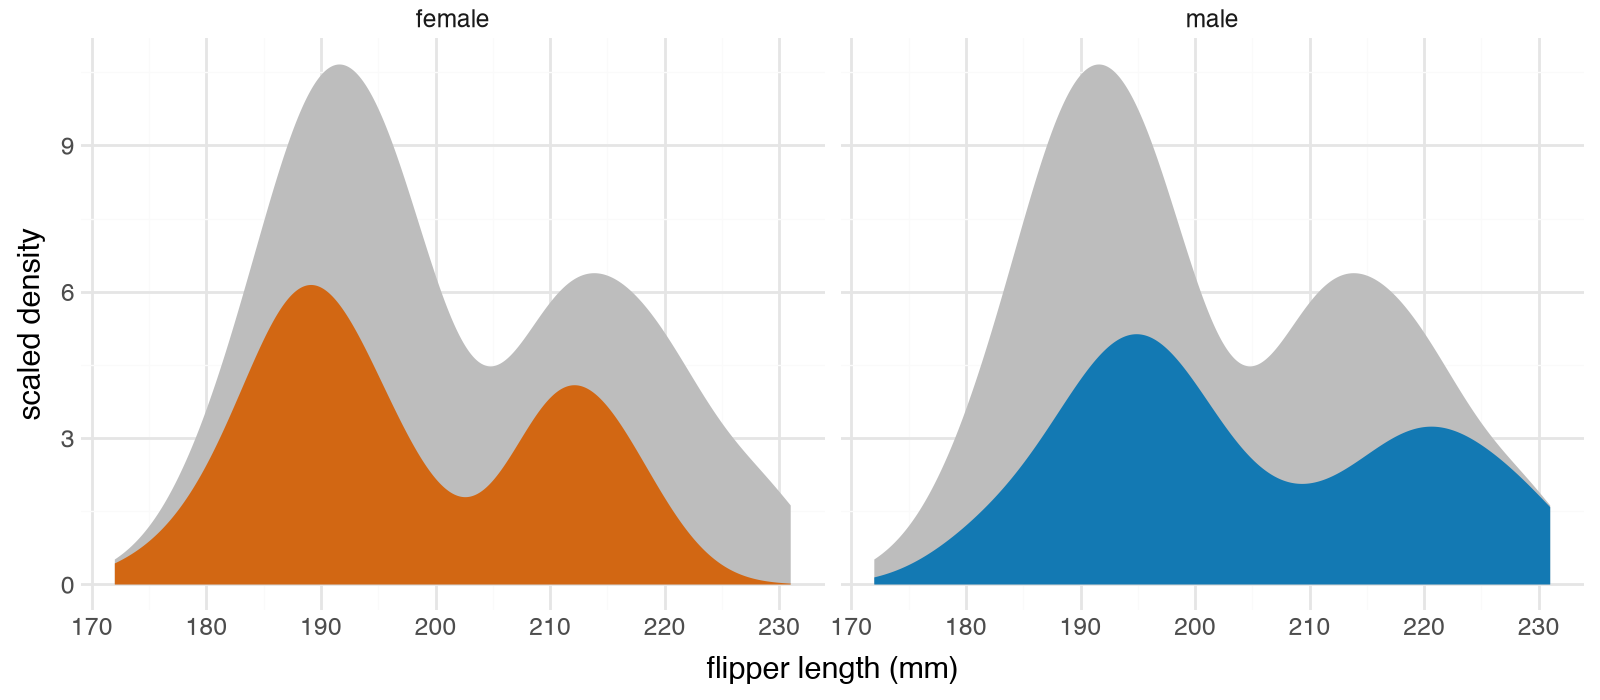

In [32]:
all_peng = peng.drop(columns="sex")    # TODO: 어떤 열을 없애야 할까요?

(
    ggplot(peng, aes(x="flipper_length_mm", y=after_stat("count")))
    + geom_density(data=all_peng, fill="#BDBDBD", color="none")        # TODO: 회색 배경 = 전체 데이터
    + geom_density(aes(fill="sex"), color="none", alpha=0.9)
    + facet_wrap("sex")                                                        # TODO: 성별로 패널 나누기
    + scale_fill_manual(values={"male": "#0072B2", "female": "#D55E00"}, guide=None)
    + labs(x="flipper length (mm)", y="scaled density")
    + theme(figure_size=(8, 3.5))
)

### 문제 5-6 (보너스) 연령 피라미드 스타일
슬라이드 50의 **연령 피라미드**처럼 수컷과 암컷의 **몸무게 히스토그램**을 좌우로 마주 보게 그려 보세요.

> 💡 힌트: 구간별 개수를 직접 세고(`pd.cut`), 한쪽 성별의 개수에 **−1을 곱한 뒤** `geom_col` + `coord_flip()`을 사용합니다.

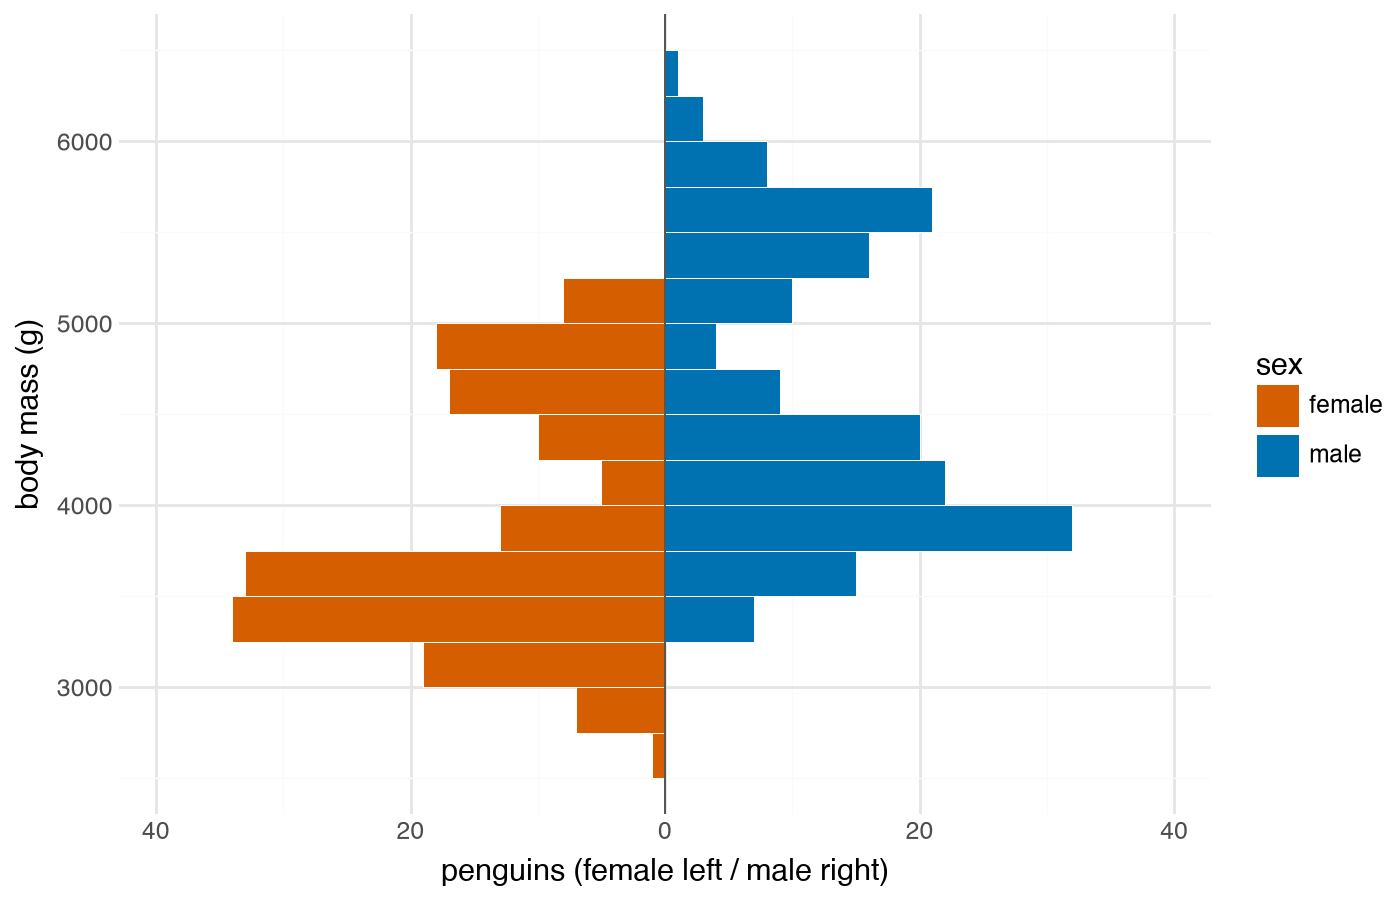

In [33]:
# ✏️ 보너스 문제 (선택)
# 같은 250g 구간을 사용해 암컷은 왼쪽, 수컷은 오른쪽으로 표시한다.
bins = np.arange(2500, 6501, 250)
pyramid_data = peng.assign(mass_bin=pd.cut(peng["body_mass_g"], bins=bins, right=False))
pyramid = (pyramid_data.groupby(["mass_bin", "sex"], observed=False)
           .size().reset_index(name="count"))
pyramid["mass_mid"] = pyramid["mass_bin"].map(lambda interval: interval.mid).astype(float)
pyramid["signed_count"] = np.where(pyramid["sex"] == "female", -pyramid["count"], pyramid["count"])
limit = int(pyramid["count"].max()) + 5
(
    ggplot(pyramid, aes(x="mass_mid", y="signed_count", fill="sex"))
    + geom_col(width=250, position="identity", color="white", size=0.2)
    + geom_hline(yintercept=0, color="#555555", size=0.4)
    + scale_y_continuous(limits=(-limit, limit), labels=lambda v: [f"{abs(x):.0f}" for x in v])
    + coord_flip()
    + scale_fill_manual(values={"female": "#D55E00", "male": "#0072B2"})
    + labs(x="body mass (g)", y="penguins (female left / male right)", fill="sex")
)

## 6. 종합 문제 📝

`plotnine.data`의 데이터셋 중 **하나를 골라** 세션에서 배운 원칙을 적용한 그래프를 **1개 이상** 그리세요.
사용 가능한 데이터셋 예시: `diamonds`, `economics`, `msleep`, `mpg`, `midwest`, `penguins`, `txhousing` 등

그래프 아래에 다음 내용을 적어 주세요.
1. 어떤 질문에 답하려는 그래프인가요?
2. 데이터 종류(수량 / 분포 등)에 맞춰 **어떤 도표**를 골랐고, 그 이유는 무엇인가요?
3. **위치 스케일**(선형 / 로그 등)과 **색상 스케일**(정성적 / 순차적 / 발산형 / 강조)을 어떻게 선택했나요?
4. 세션에서 본 *ugly / bad / wrong* 사례 중 피하려고 신경 쓴 부분이 있다면 적어 주세요.

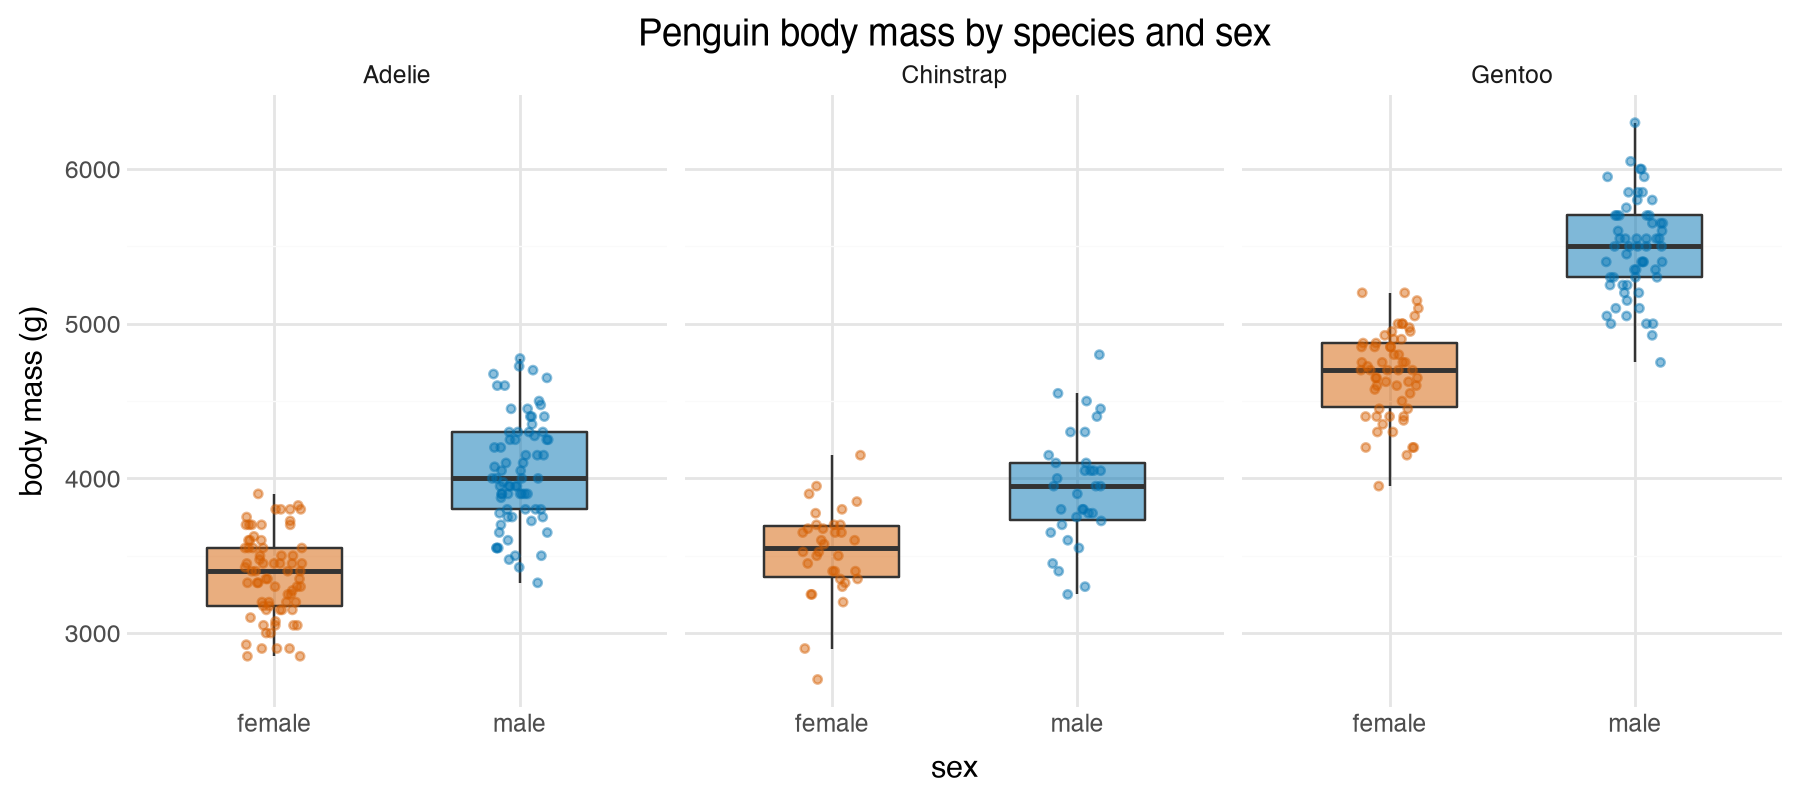

In [34]:
# 종합: 종별로 성별 몸무게 분포가 어떻게 다른가?
# 상자도표로 중앙값과 산포를, 관측점으로 표본 수와 실제 분포를 함께 보여준다.
(
    ggplot(peng, aes(x="sex", y="body_mass_g", fill="sex"))
    + geom_boxplot(width=0.55, alpha=0.5, outlier_shape="")
    + geom_jitter(aes(color="sex"), width=0.12, height=0,
                  alpha=0.45, size=1.2, random_state=42)
    + facet_wrap("species", nrow=1)
    + scale_x_discrete(limits=["female", "male"])
    + scale_fill_manual(values={"female": "#D55E00", "male": "#0072B2"}, guide=None)
    + scale_color_manual(values={"female": "#D55E00", "male": "#0072B2"}, guide=None)
    + labs(x="sex", y="body mass (g)", title="Penguin body mass by species and sex")
    + theme(figure_size=(9, 4))
)

**✍️ 답:**
1. **질문:** 펭귄의 각 종에서 수컷과 암컷의 몸무게 분포가 어떻게 다른지 알아보려는 그래프이다. 세 종 모두 수컷의 몸무게 중앙값이 암컷보다 높고, Gentoo는 다른 두 종보다 전반적으로 무겁다.
2. **도표:** 범주별 연속형 변수의 분포를 비교하므로 상자도표를 사용해 중앙값·사분위 범위·산포를 요약하고, 반투명한 관측점을 겹쳐 실제 관측값과 겹침을 보여주었다. 종별로 패널을 나누어 여섯 집단을 한꺼번에 겹칠 때의 혼잡을 줄였다.
3. **스케일:** 몸무게의 g 단위 차이를 직접 비교할 수 있도록 선형 위치 스케일과 모든 패널에서 동일한 y축을 사용했다. 성별은 순서가 없는 범주이므로 주황·파랑의 정성적 색상을 사용하고, x축에도 성별을 표시했다.
4. **피하려고 한 문제:** 무지개색이나 불필요한 색상으로 시선을 분산시키는 조악함, 패널마다 다른 축으로 차이를 오해하게 하는 표현, 겹친 점 때문에 관측값이 가려지는 문제를 피했다. 점은 x방향으로만 조금 흩뿌려 실제 몸무게 값은 바꾸지 않았고, 상자도표의 별도 이상치 기호는 숨겨 관측점을 중복 표시하지 않았다. 결측치가 제거된 `peng`의 관측치만 사용하므로 결과는 이 분석 표본에 대한 해석이다.

## ⚙️ 생성형 AI 활용 (비판적 사용)

AI는 **검산기·설명 도우미**로 활용하고 최종 판단은 본인이 합니다.

- **어디에 썼나** (PyTorch 문법 디버깅·개념 설명·에러 해석 등 구체적으로): (여기에 답)

- **AI가 이 실험에는 틀린 답을 준 사례**
  본인이 겪은 사례와, 그것을 **어떻게 알아채고 고쳤는지**(본인 출력값과 대조 / 공식 문서 확인 / 직접 실험) 적으세요: (여기에 답)

- **실제 대화 내역** 붙여넣기:

```
(여기에 AI와의 실제 대화 내역을 붙여넣기)
```

- 마지막 한 문장: **AI가 대신할 수 없었던 나만의 판단**은 무엇이었나요? (여기에 답)

---
### 수고하셨습니다! 🎉
제출 전 **런타임 → 모두 실행**으로 모든 셀이 에러 없이 실행되는지 확인해 주세요.